In [33]:
!pip install numpy pandas scikit-learn notebook



[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [34]:
!pip install pyarrow


[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [35]:
!pip install matplotlib


[notice] A new release of pip is available: 25.3 -> 26.1
[notice] To update, run: pip install --upgrade pip


In [36]:
# ============================================================
# COMPARAÇÃO DIRETA:
# 1) WiSARD simples por contagem
# 2) KalmanWiSARD
# TUDO EM UMA ÚNICA CÉLULA
# ============================================================

# Importa NumPy para operações numéricas.
import numpy as np

# Importa pandas para organizar os resultados em t
# abelas.
import pandas as pd

# Importa defaultdict para criar dicionários com valores padrão automáticos.
from collections import defaultdict

# Importa train_test_split para separar treino e teste.
from sklearn.model_selection import train_test_split

# Importa accuracy_score para calcular acurácia.
from sklearn.metrics import accuracy_score

# Importa o dataset Wine para o experimento.
from sklearn.datasets import load_wine


# ============================================================
# ENCODER: THERMOMETER ENCODING
# ============================================================

class ThermometerEncoder:
    # Define a classe de codificação thermometer.
    def __init__(self, minimum, maximum, resolution):
        # Guarda o valor mínimo observado para o atributo.
        self.minimum = minimum
        
        # Guarda o valor máximo observado para o atributo.
        self.maximum = maximum
        
        # Guarda a quantidade de bits usada para codificar o atributo.
        self.resolution = resolution
        
        # Calcula o intervalo do atributo e soma epsilon para evitar divisão por zero.
        self.range = (maximum - minimum) + 1e-9

    def encode_value(self, value):
        # Recebe um valor escalar e o transforma em vetor thermometer.
        
        # Faz clipping do valor para dentro do intervalo conhecido.
        value = np.clip(value, self.minimum, self.maximum)
        
        # Normaliza o valor para o intervalo [0, 1].
        normalized = (value - self.minimum) / self.range
        
        # Converte o valor normalizado em quantidade de bits ligados.
        k = int(normalized * self.resolution)
        
        # Garante que k fique entre 0 e resolution.
        k = min(max(k, 0), self.resolution)
        
        # Cria um vetor de zeros com tamanho igual à resolução.
        bits = np.zeros(self.resolution, dtype=np.uint8)
        
        # Liga os k primeiros bits.
        bits[:k] = 1
        
        # Retorna o vetor binário.
        return bits


# ============================================================
# CLASSE BASE COM LÓGICA COMPARTILHADA
# ============================================================

class BaseWiSARD:
    # Define uma classe base com a lógica compartilhada entre os modelos.
    def __init__(self, address_size=4, resolution=16, seed=42):
        # Guarda o número de bits por RAM.
        self.address_size = address_size
        
        # Guarda a resolução do thermometer encoding.
        self.resolution = resolution
        
        # Guarda a seed aleatória.
        self.seed = seed
        
        # Cria o gerador aleatório.
        self.rng = np.random.default_rng(self.seed)
        
        # Inicializa lista de classes.
        self.classes_ = None
        
        # Inicializa encoders por atributo.
        self.encoders_ = None
        
        # Inicializa o mapeamento entre bits e RAMs.
        self.mapping_ = None
        
        # Inicializa o número de RAMs.
        self.n_rams_ = None
        
        # Inicializa a dimensão binária.
        self.n_bits_ = None

    def _fit_encoders(self, X):
        # Ajusta um encoder para cada atributo.
        
        # Calcula mínimos por coluna.
        mins = X.min(axis=0)
        
        # Calcula máximos por coluna.
        maxs = X.max(axis=0)
        
        # Cria a lista de encoders, um por atributo.
        self.encoders_ = [
            ThermometerEncoder(mins[j], maxs[j], self.resolution)
            for j in range(X.shape[1])
        ]

    def _encode_sample(self, sample):
        # Codifica uma amostra inteira em vetor binário.
        
        # Cria uma lista para armazenar os blocos codificados.
        encoded_parts = []
        
        # Percorre cada atributo da amostra.
        for j, value in enumerate(sample):
            # Codifica o valor do atributo j.
            encoded_value = self.encoders_[j].encode_value(value)
            
            # Adiciona o bloco codificado à lista.
            encoded_parts.append(encoded_value)
        
        # Concatena todos os blocos em um único vetor.
        return np.concatenate(encoded_parts)

    def _encode_dataset(self, X):
        # Codifica um conjunto inteiro de amostras.
        
        # Codifica cada amostra e empilha o resultado em matriz.
        return np.array([self._encode_sample(sample) for sample in X], dtype=np.uint8)

    def _build_mapping(self, n_bits):
        # Constrói o mapeamento aleatório de bits para RAMs.
        
        # Guarda a quantidade total de bits binários.
        self.n_bits_ = n_bits
        
        # Calcula quantas RAMs serão necessárias.
        self.n_rams_ = int(np.ceil(n_bits / self.address_size))
        
        # Calcula o total de posições após padding.
        total_positions = self.n_rams_ * self.address_size
        
        # Cria os índices reais dos bits.
        indices = np.arange(n_bits)
        
        # Calcula quantos índices extras serão necessários.
        extra = total_positions - n_bits
        
        # Se faltar bits para preencher todas as RAMs.
        if extra > 0:
            # Sorteia índices extras com reposição.
            extra_indices = self.rng.choice(indices, size=extra, replace=True)
            
            # Concatena os índices reais com os extras.
            indices = np.concatenate([indices, extra_indices])
        
        # Embaralha os índices.
        self.rng.shuffle(indices)
        
        # Reorganiza os índices em formato de RAMs x address_size.
        self.mapping_ = indices.reshape(self.n_rams_, self.address_size)

    def _bits_to_address(self, bits):
        # Converte um pequeno vetor de bits em um inteiro.
        
        # Inicializa o endereço com zero.
        address = 0
        
        # Percorre os bits.
        for bit in bits:
            # Desloca à esquerda e incorpora o novo bit.
            address = (address << 1) | int(bit)
        
        # Retorna o endereço calculado.
        return address

    def _get_addresses(self, encoded_sample):
        # Obtém todos os endereços ativados pelas RAMs para uma amostra binária.
        
        # Cria uma lista para armazenar os endereços.
        addresses = []
        
        # Percorre cada RAM.
        for ram_idx in range(self.n_rams_):
            # Recupera os índices de bits associados à RAM.
            bit_indices = self.mapping_[ram_idx]
            
            # Seleciona os bits correspondentes.
            selected_bits = encoded_sample[bit_indices]
            
            # Converte os bits em endereço.
            address = self._bits_to_address(selected_bits)
            
            # Adiciona o endereço à lista.
            addresses.append(address)
        
        # Retorna a lista de endereços.
        return addresses


# ============================================================
# BASELINE: WISARD SIMPLES POR CONTAGEM
# ============================================================

class SimpleWiSARD(BaseWiSARD):
    # Define a WiSARD simples baseada em contagem.
    def __init__(self, address_size=4, resolution=16, seed=42, use_negative_update=False):
        # Inicializa a classe base.
        super().__init__(address_size=address_size, resolution=resolution, seed=seed)
        
        # Guarda se haverá atualização negativa.
        self.use_negative_update = use_negative_update
        
        # Inicializa a memória de contagens.
        self.memory_ = None

    def fit(self, X, y):
        # Treina a WiSARD simples.
        
        # Converte X para array NumPy float.
        X = np.asarray(X, dtype=float)
        
        # Converte y para array NumPy.
        y = np.asarray(y)
        
        # Descobre as classes.
        self.classes_ = np.unique(y)
        
        # Ajusta os encoders aos dados.
        self._fit_encoders(X)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Constrói o mapeamento de bits para RAMs.
        self._build_mapping(Xb.shape[1])
        
        # Cria a memória de contagens:
        # classe -> lista de RAMs -> dicionário endereço -> contagem
        self.memory_ = {
            c: [defaultdict(float) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Percorre cada amostra de treino.
        for i in range(len(Xb)):
            # Recupera a amostra binária.
            xb = Xb[i]
            
            # Recupera a classe correta.
            y_true = y[i]
            
            # Obtém os endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Atualização positiva: soma 1 na classe correta.
            for ram_idx, address in enumerate(addresses):
                # Incrementa a contagem da classe correta.
                self.memory_[y_true][ram_idx][address] += 1.0
            
            # Se a atualização negativa estiver habilitada.
            if self.use_negative_update:
                # Percorre todas as outras classes.
                for other_class in self.classes_:
                    # Ignora a classe correta.
                    if other_class == y_true:
                        continue
                    
                    # Percorre cada endereço ativado.
                    for ram_idx, address in enumerate(addresses):
                        # Decrementa a contagem da classe incorreta.
                        self.memory_[other_class][ram_idx][address] -= 1.0
        
        # Retorna o próprio modelo.
        return self

    def predict(self, X):
        # Prediz as classes para um conjunto de amostras.
        
        # Converte X para array NumPy float.
        X = np.asarray(X, dtype=float)
        
        # Codifica as amostras.
        Xb = self._encode_dataset(X)
        
        # Cria lista para armazenar predições.
        predictions = []
        
        # Percorre cada amostra binária.
        for xb in Xb:
            # Obtém os endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Cria um dicionário de scores por classe.
            scores = {}
            
            # Percorre cada classe.
            for c in self.classes_:
                # Inicializa o score da classe.
                score = 0.0
                
                # Soma as contagens das posições ativadas.
                for ram_idx, address in enumerate(addresses):
                    score += self.memory_[c][ram_idx][address]
                
                # Guarda o score da classe.
                scores[c] = score
            
            # Seleciona a classe com maior score.
            pred = max(scores, key=scores.get)
            
            # Adiciona a predição à lista.
            predictions.append(pred)
        
        # Retorna as predições como array NumPy.
        return np.array(predictions)


# ============================================================
# MODELO PROPOSTO: KALMAN-WISARD
# ============================================================

class KalmanWiSARD(BaseWiSARD):
    # Define a WiSARD com atualização por filtro de Kalman.
    def __init__(
        self,
        address_size=4,
        resolution=16,
        q=1e-3,
        r=5e-2,
        p0=1.0,
        n_epochs=1,
        seed=42,
        use_negative_update=False
    ):
        # Inicializa a classe base.
        super().__init__(address_size=address_size, resolution=resolution, seed=seed)
        
        # Guarda o ruído de processo.
        self.q = q
        
        # Guarda o ruído de observação.
        self.r = r
        
        # Guarda a incerteza inicial.
        self.p0 = p0
        
        # Guarda o número de épocas.
        self.n_epochs = n_epochs
        
        # Guarda se usa atualização negativa.
        self.use_negative_update = use_negative_update
        
        # Inicializa memória de estados.
        self.memory_x_ = None
        
        # Inicializa memória de incertezas.
        self.memory_p_ = None

    def _kalman_update(self, current_x, current_p, z):
        # Realiza uma atualização escalar do filtro de Kalman.
        
        # Predição do estado.
        x_pred = current_x
        
        # Predição da incerteza.
        p_pred = current_p + self.q
        
        # Cálculo do ganho de Kalman.
        k_gain = p_pred / (p_pred + self.r)
        
        # Atualização do estado.
        updated_x = x_pred + k_gain * (z - x_pred)
        
        # Atualização da incerteza.
        updated_p = (1.0 - k_gain) * p_pred
        
        # Retorna estado e incerteza atualizados.
        return updated_x, updated_p

    def fit(self, X, y):
        # Treina a Kalman-WiSARD.
        
        # Converte X para array NumPy float.
        X = np.asarray(X, dtype=float)
        
        # Converte y para array NumPy.
        y = np.asarray(y)
        
        # Descobre as classes.
        self.classes_ = np.unique(y)
        
        # Ajusta os encoders.
        self._fit_encoders(X)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Constrói o mapeamento das RAMs.
        self._build_mapping(Xb.shape[1])
        
        # Cria a memória de estados:
        # classe -> lista de RAMs -> dicionário endereço -> estado
        self.memory_x_ = {
            c: [defaultdict(float) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Cria a memória de incertezas:
        # classe -> lista de RAMs -> dicionário endereço -> incerteza
        self.memory_p_ = {
            c: [defaultdict(lambda: self.p0) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Repete o treinamento por várias épocas.
        for epoch in range(self.n_epochs):
            # Embaralha a ordem das amostras.
            indices = self.rng.permutation(len(Xb))
            
            # Percorre as amostras na ordem embaralhada.
            for idx in indices:
                # Recupera a amostra binária.
                xb = Xb[idx]
                
                # Recupera a classe correta.
                y_true = y[idx]
                
                # Obtém os endereços ativados.
                addresses = self._get_addresses(xb)
                
                # Atualização positiva na classe correta.
                for ram_idx, address in enumerate(addresses):
                    # Lê o estado atual.
                    current_x = self.memory_x_[y_true][ram_idx][address]
                    
                    # Lê a incerteza atual.
                    current_p = self.memory_p_[y_true][ram_idx][address]
                    
                    # Define a observação positiva.
                    z = 1.0
                    
                    # Atualiza estado e incerteza via Kalman.
                    new_x, new_p = self._kalman_update(current_x, current_p, z)
                    
                    # Salva o novo estado.
                    self.memory_x_[y_true][ram_idx][address] = new_x
                    
                    # Salva a nova incerteza.
                    self.memory_p_[y_true][ram_idx][address] = new_p
                
                # Se atualização negativa estiver ativada.
                if self.use_negative_update:
                    # Percorre as outras classes.
                    for other_class in self.classes_:
                        # Ignora a classe correta.
                        if other_class == y_true:
                            continue
                        
                        # Atualiza as classes incorretas com z = 0.
                        for ram_idx, address in enumerate(addresses):
                            # Lê estado atual da classe incorreta.
                            current_x = self.memory_x_[other_class][ram_idx][address]
                            
                            # Lê incerteza atual da classe incorreta.
                            current_p = self.memory_p_[other_class][ram_idx][address]
                            
                            # Define observação negativa.
                            z = 0.0
                            
                            # Atualiza estado e incerteza.
                            new_x, new_p = self._kalman_update(current_x, current_p, z)
                            
                            # Salva o novo estado.
                            self.memory_x_[other_class][ram_idx][address] = new_x
                            
                            # Salva a nova incerteza.
                            self.memory_p_[other_class][ram_idx][address] = new_p
        
        # Retorna o modelo treinado.
        return self

    def predict(self, X):
        # Prediz as classes para um conjunto de amostras.
        
        # Converte X para array NumPy float.
        X = np.asarray(X, dtype=float)
        
        # Codifica as amostras.
        Xb = self._encode_dataset(X)
        
        # Cria lista para guardar as predições.
        predictions = []
        
        # Percorre cada amostra binária.
        for xb in Xb:
            # Obtém os endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Cria dicionário de scores.
            scores = {}
            
            # Percorre cada classe.
            for c in self.classes_:
                # Inicializa o score da classe.
                score = 0.0
                
                # Soma os estados das posições ativadas.
                for ram_idx, address in enumerate(addresses):
                    score += self.memory_x_[c][ram_idx][address]
                
                # Guarda o score calculado.
                scores[c] = score
            
            # Seleciona a classe de maior score.
            pred = max(scores, key=scores.get)
            
            # Armazena a predição.
            predictions.append(pred)
        
        # Retorna as predições como array NumPy.
        return np.array(predictions)


# ============================================================
# FUNÇÃO DE AVALIAÇÃO
# ============================================================

def evaluate_model(model_class, model_params, X, y, seeds=(0, 1, 2)):
    # Avalia um modelo em múltiplas seeds e retorna as acurácias.
    
    # Cria uma lista para armazenar as acurácias.
    accuracies = []
    
    # Percorre cada seed.
    for seed in seeds:
        # Divide dados em treino e teste com seed fixa.
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.30,
            random_state=seed,
            stratify=y
        )
        
        # Cria o modelo com os parâmetros fornecidos.
        model = model_class(seed=seed, **model_params)
        
        # Treina o modelo.
        model.fit(X_train, y_train)
        
        # Faz predições no teste.
        y_pred = model.predict(X_test)
        
        # Calcula a acurácia.
        acc = accuracy_score(y_test, y_pred)
        
        # Adiciona a acurácia à lista.
        accuracies.append(acc)
    
    # Retorna a lista de acurácias.
    return accuracies


# ============================================================
# CARREGAMENTO DOS DADOS
# ============================================================

# Carrega o dataset Wine.
data = load_wine()

# Extrai a matriz de atributos.
X = data.data

# Extrai o vetor de rótulos.
y = data.target


# ============================================================
# MELHOR CONFIGURAÇÃO ENCONTRADA PARA A KALMAN-WISARD
# ============================================================

# Define os parâmetros da melhor configuração que você encontrou.
best_kalman_params = {
    "address_size": 4,             # melhor address size encontrado
    "resolution": 16,              # melhor resolução encontrada
    "q": 1e-3,                     # melhor q encontrado
    "r": 5e-2,                     # melhor r encontrado
    "p0": 1.0,                     # incerteza inicial
    "n_epochs": 1,                 # mesmo valor usado no script compacto
    "use_negative_update": False   # melhor resultado foi sem atualização negativa
}

# Define os parâmetros do baseline simples usando a mesma estrutura.
baseline_params = {
    "address_size": 4,             # mantém o mesmo tamanho de endereço
    "resolution": 16,              # mantém a mesma resolução
    "use_negative_update": False   # para comparação justa, sem atualização negativa
}


# ============================================================
# EXECUÇÃO DOS EXPERIMENTOS
# ============================================================

# Define as seeds usadas na comparação.
seeds = (0, 1, 2, 3, 4)

# Avalia o baseline WiSARD simples.
baseline_accs = evaluate_model(
    model_class=SimpleWiSARD,
    model_params=baseline_params,
    X=X,
    y=y,
    seeds=seeds
)

# Avalia a Kalman-WiSARD.
kalman_accs = evaluate_model(
    model_class=KalmanWiSARD,
    model_params=best_kalman_params,
    X=X,
    y=y,
    seeds=seeds
)


# ============================================================
# TABELA COMPARATIVA FINAL
# ============================================================

# Cria um DataFrame com os resultados resumidos.
comparison_df = pd.DataFrame([
    {
        "modelo": "WiSARD simples",
        "address_size": baseline_params["address_size"],
        "resolution": baseline_params["resolution"],
        "q": np.nan,
        "r": np.nan,
        "n_epochs": 1,
        "use_negative_update": baseline_params["use_negative_update"],
        "mean_accuracy": float(np.mean(baseline_accs)),
        "std_accuracy": float(np.std(baseline_accs)),
        "all_accuracies": baseline_accs
    },
    {
        "modelo": "Kalman-WiSARD",
        "address_size": best_kalman_params["address_size"],
        "resolution": best_kalman_params["resolution"],
        "q": best_kalman_params["q"],
        "r": best_kalman_params["r"],
        "n_epochs": best_kalman_params["n_epochs"],
        "use_negative_update": best_kalman_params["use_negative_update"],
        "mean_accuracy": float(np.mean(kalman_accs)),
        "std_accuracy": float(np.std(kalman_accs)),
        "all_accuracies": kalman_accs
    }
])

# Ordena a tabela pelo melhor desempenho médio.
comparison_df = comparison_df.sort_values(
    by=["mean_accuracy", "std_accuracy"],
    ascending=[False, True]
).reset_index(drop=True)

# Imprime um título para os resultados.
print("===== COMPARAÇÃO FINAL =====")

# Imprime a tabela completa.
print(comparison_df)

# Calcula a diferença entre as médias de acurácia.
gain = float(np.mean(kalman_accs) - np.mean(baseline_accs))

# Imprime a diferença de desempenho.
print("\nGanho médio da Kalman-WiSARD sobre a WiSARD simples:", gain)


# ============================================================
# IMPRESSÃO DETALHADA DOS RESULTADOS
# ============================================================

# Imprime as acurácias do baseline.
print("\nAcurácias da WiSARD simples por seed:")
print(baseline_accs)

# Imprime as acurácias da Kalman-WiSARD.
print("\nAcurácias da Kalman-WiSARD por seed:")
print(kalman_accs)

# Imprime a média do baseline.
print("\nMédia WiSARD simples:", float(np.mean(baseline_accs)))

# Imprime o desvio-padrão do baseline.
print("Desvio-padrão WiSARD simples:", float(np.std(baseline_accs)))

# Imprime a média da Kalman-WiSARD.
print("\nMédia Kalman-WiSARD:", float(np.mean(kalman_accs)))

# Imprime o desvio-padrão da Kalman-WiSARD.
print("Desvio-padrão Kalman-WiSARD:", float(np.std(kalman_accs)))

===== COMPARAÇÃO FINAL =====
           modelo  address_size  resolution      q     r  n_epochs  \
0   Kalman-WiSARD             4          16  0.001  0.05         1   
1  WiSARD simples             4          16    NaN   NaN         1   

   use_negative_update  mean_accuracy  std_accuracy  \
0                False       0.974074      0.009072   
1                False       0.948148      0.041243   

                                      all_accuracies  
0  [0.9814814814814815, 0.9629629629629629, 0.981...  
1  [0.9814814814814815, 0.9074074074074074, 0.981...  

Ganho médio da Kalman-WiSARD sobre a WiSARD simples: 0.02592592592592602

Acurácias da WiSARD simples por seed:
[0.9814814814814815, 0.9074074074074074, 0.9814814814814815, 0.9814814814814815, 0.8888888888888888]

Acurácias da Kalman-WiSARD por seed:
[0.9814814814814815, 0.9629629629629629, 0.9814814814814815, 0.9629629629629629, 0.9814814814814815]

Média WiSARD simples: 0.9481481481481481
Desvio-padrão WiSARD simples: 0.04

In [37]:
# ============================================================
# GRÁFICOS DOS RESULTADOS
# TUDO EM UMA ÚNICA CÉLULA
# ============================================================

# Importa NumPy para operações numéricas.
import numpy as np

# Importa pandas para manipular tabelas.
import pandas as pd

# Importa matplotlib para gerar os gráficos.
import matplotlib.pyplot as plt


In [38]:
# ============================================================
# DADOS DOS RESULTADOS JÁ OBTIDOS
# ============================================================

# Define as acurácias da WiSARD simples obtidas nas seeds.
baseline_accs = [0.9814814814814815, 0.9074074074074074, 0.9814814814814815, 0.9814814814814815, 0.8888888888888888]

# Define as acurácias da Kalman-WiSARD obtidas nas seeds.
kalman_accs = [0.9814814814814815, 0.9629629629629629, 0.9814814814814815, 0.9629629629629629, 0.9814814814814815]

# Define a lista de seeds apenas para usar no eixo x.
seeds = [0, 1, 2, 3, 4]

# Calcula a média da WiSARD simples.
baseline_mean = np.mean(baseline_accs)

# Calcula o desvio-padrão da WiSARD simples.
baseline_std = np.std(baseline_accs)

# Calcula a média da Kalman-WiSARD.
kalman_mean = np.mean(kalman_accs)

# Calcula o desvio-padrão da Kalman-WiSARD.
kalman_std = np.std(kalman_accs)



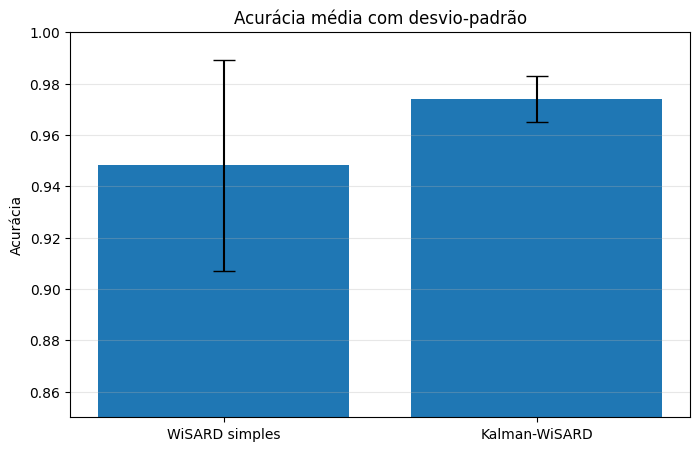

In [39]:
# ============================================================
# GRÁFICO 1: BARRAS COM MÉDIA E DESVIO-PADRÃO
# ============================================================

# Cria uma nova figura.
plt.figure(figsize=(8, 5))

# Define os nomes dos modelos.
models = ["WiSARD simples", "Kalman-WiSARD"]

# Define as médias dos modelos.
means = [baseline_mean, kalman_mean]

# Define os desvios-padrão dos modelos.
stds = [baseline_std, kalman_std]

# Cria o gráfico de barras com barras de erro.
plt.bar(models, means, yerr=stds, capsize=8)

# Define o título do gráfico.
plt.title("Acurácia média com desvio-padrão")

# Define o rótulo do eixo y.
plt.ylabel("Acurácia")

# Define o limite do eixo y para destacar melhor as diferenças.
plt.ylim(0.85, 1.00)

# Adiciona uma grade horizontal leve.
plt.grid(axis="y", alpha=0.3)

# Exibe o gráfico.
plt.show()



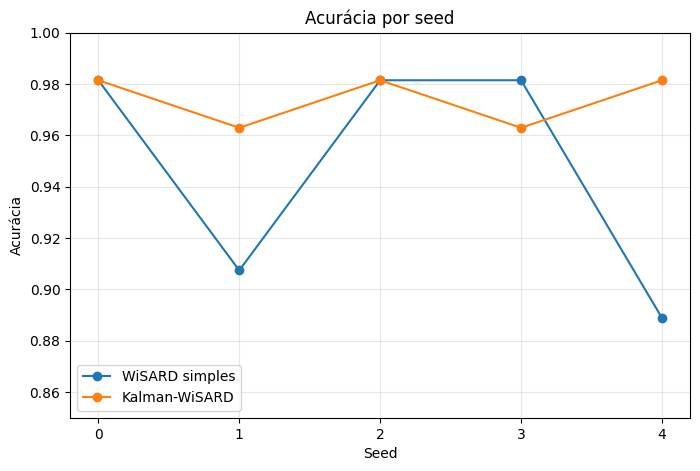

In [40]:
# ============================================================
# GRÁFICO 2: ACURÁCIA POR SEED
# ============================================================

# Cria uma nova figura.
plt.figure(figsize=(8, 5))

# Plota a curva da WiSARD simples.
plt.plot(seeds, baseline_accs, marker="o", label="WiSARD simples")

# Plota a curva da Kalman-WiSARD.
plt.plot(seeds, kalman_accs, marker="o", label="Kalman-WiSARD")

# Define o título do gráfico.
plt.title("Acurácia por seed")

# Define o rótulo do eixo x.
plt.xlabel("Seed")

# Define o rótulo do eixo y.
plt.ylabel("Acurácia")

# Define os ticks do eixo x.
plt.xticks(seeds)

# Define o limite do eixo y.
plt.ylim(0.85, 1.00)

# Adiciona grade.
plt.grid(alpha=0.3)

# Mostra a legenda.
plt.legend()

# Exibe o gráfico.
plt.show()




/tmp/ipykernel_35352/1163137739.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


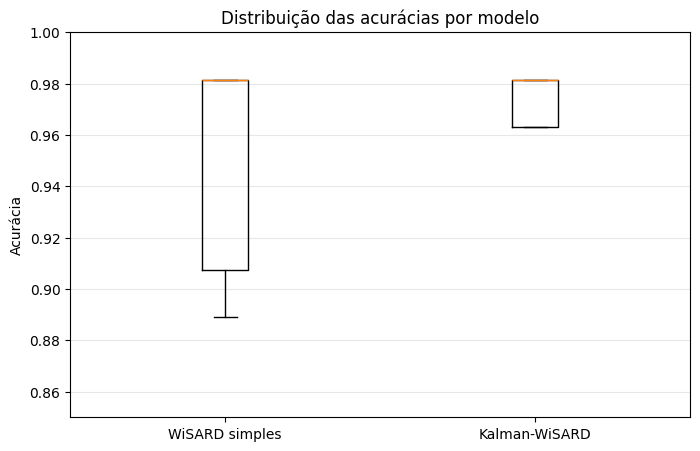

In [41]:
# ============================================================
# GRÁFICO 3: BOXPLOT DAS ACURÁCIAS
# ============================================================

# Cria uma nova figura.
plt.figure(figsize=(8, 5))

# Cria o boxplot com os dois conjuntos de acurácia.
plt.boxplot(
    [baseline_accs, kalman_accs],
    labels=["WiSARD simples", "Kalman-WiSARD"]
)

# Define o título do gráfico.
plt.title("Distribuição das acurácias por modelo")

# Define o rótulo do eixo y.
plt.ylabel("Acurácia")

# Define o limite do eixo y.
plt.ylim(0.85, 1.00)

# Adiciona grade horizontal.
plt.grid(axis="y", alpha=0.3)

# Exibe o gráfico.
plt.show()




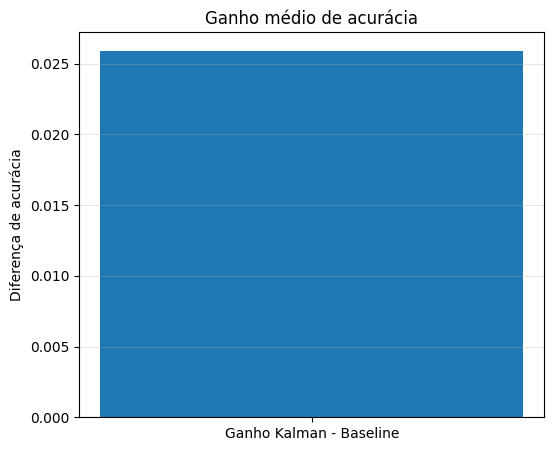

In [42]:
# ============================================================
# GRÁFICO 4: GANHO MÉDIO ENTRE OS MODELOS
# ============================================================

# Calcula o ganho médio do modelo Kalman em relação ao baseline.
gain = kalman_mean - baseline_mean

# Cria uma nova figura.
plt.figure(figsize=(6, 5))

# Cria um gráfico de barra para o ganho.
plt.bar(["Ganho Kalman - Baseline"], [gain])

# Define o título do gráfico.
plt.title("Ganho médio de acurácia")

# Define o rótulo do eixo y.
plt.ylabel("Diferença de acurácia")

# Adiciona grade horizontal.
plt.grid(axis="y", alpha=0.3)

# Exibe o gráfico.
plt.show()

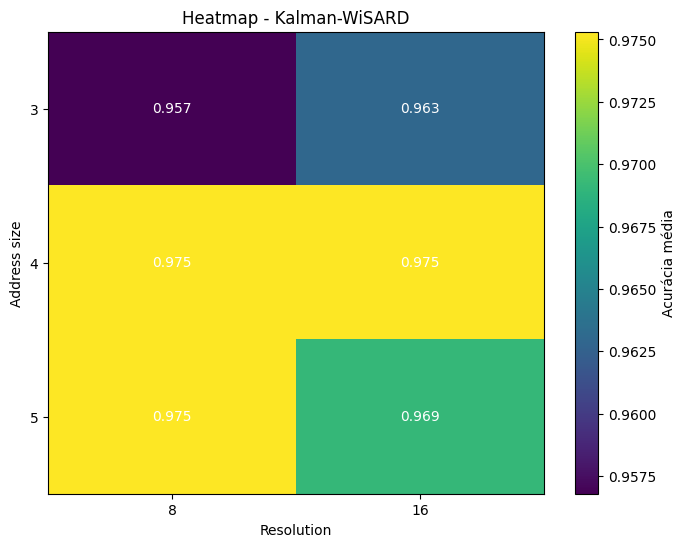

In [43]:
# ============================================================
# HEATMAP RECOMPUTANDO RESULTADOS (SEM results_df)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine

# ============================================================
# PARÂMETROS (os mais relevantes)
# ============================================================

address_sizes = [3, 4, 5]
resolutions = [8, 16]

# Usando os melhores parâmetros de Kalman que você encontrou
q = 1e-3
r = 5e-2

# Número de seeds para média
seeds = [0, 1, 2]

# ============================================================
# CARREGA DADOS
# ============================================================

data = load_wine()
X = data.data
y = data.target

# ============================================================
# MATRIZ PARA O HEATMAP
# ============================================================

heatmap = np.zeros((len(address_sizes), len(resolutions)))

# ============================================================
# LOOP PRINCIPAL
# ============================================================

for i, addr in enumerate(address_sizes):
    for j, res in enumerate(resolutions):

        accs = []

        for seed in seeds:
            # split
            Xtr, Xte, ytr, yte = train_test_split(
                X, y, test_size=0.3, stratify=y, random_state=seed
            )

            # modelo
            model = KalmanWiSARD(
                address_size=addr,
                resolution=res,
                q=q,
                r=r,
                p0=1.0,
                n_epochs=1,
                seed=seed,
                use_negative_update=False
            )

            model.fit(Xtr, ytr)
            pred = model.predict(Xte)

            accs.append(accuracy_score(yte, pred))

        # média das seeds
        heatmap[i, j] = np.mean(accs)

# ============================================================
# PLOT
# ============================================================

plt.figure(figsize=(8, 6))

plt.imshow(heatmap, aspect="auto")

plt.colorbar(label="Acurácia média")

plt.xticks(np.arange(len(resolutions)), resolutions)
plt.yticks(np.arange(len(address_sizes)), address_sizes)

plt.xlabel("Resolution")
plt.ylabel("Address size")
plt.title("Heatmap - Kalman-WiSARD")

# escreve valores dentro dos quadrados
for i in range(len(address_sizes)):
    for j in range(len(resolutions)):
        plt.text(j, i, f"{heatmap[i, j]:.3f}",
                 ha="center", va="center", color="white")

plt.show()

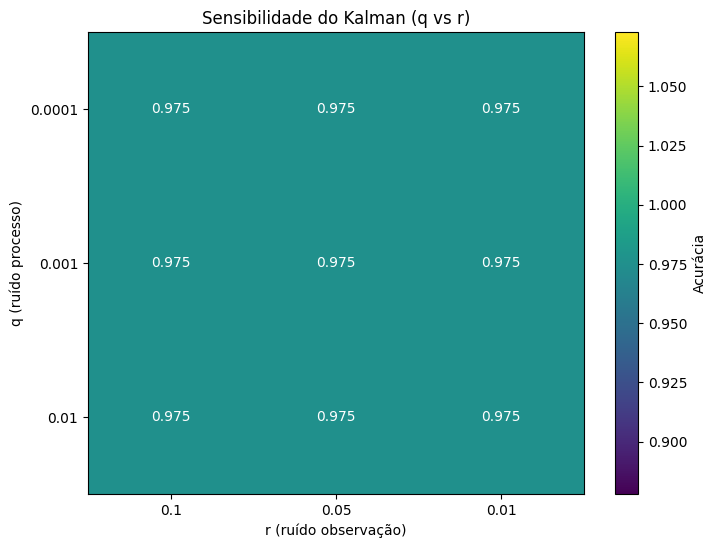

In [44]:
# ============================================================
# HEATMAP: IMPACTO DOS PARÂMETROS q e r
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine

# Dados
data = load_wine()
X = data.data
y = data.target

# Fixando os melhores parâmetros estruturais
address_size = 4
resolution = 16

# Grade de parâmetros Kalman
q_values = [1e-4, 1e-3, 1e-2]
r_values = [1e-1, 5e-2, 1e-2]

seeds = [0, 1, 2]

heatmap = np.zeros((len(q_values), len(r_values)))

# Loop
for i, q in enumerate(q_values):
    for j, r in enumerate(r_values):

        accs = []

        for seed in seeds:
            Xtr, Xte, ytr, yte = train_test_split(
                X, y, test_size=0.3, stratify=y, random_state=seed
            )

            model = KalmanWiSARD(
                address_size=address_size,
                resolution=resolution,
                q=q,
                r=r,
                p0=1.0,
                n_epochs=1,
                seed=seed,
                use_negative_update=False
            )

            model.fit(Xtr, ytr)
            pred = model.predict(Xte)
            accs.append(accuracy_score(yte, pred))

        heatmap[i, j] = np.mean(accs)

# Plot
plt.figure(figsize=(8, 6))

plt.imshow(heatmap, aspect="auto")
plt.colorbar(label="Acurácia")

plt.xticks(np.arange(len(r_values)), r_values)
plt.yticks(np.arange(len(q_values)), q_values)

plt.xlabel("r (ruído observação)")
plt.ylabel("q (ruído processo)")
plt.title("Sensibilidade do Kalman (q vs r)")

# valores no gráfico
for i in range(len(q_values)):
    for j in range(len(r_values)):
        plt.text(j, i, f"{heatmap[i, j]:.3f}",
                 ha="center", va="center", color="white")

plt.show()

In [45]:
#versão com métricas de custo

===== COMPARAÇÃO FINAL =====
           modelo  address_size  resolution      q     r  n_epochs  \
0   Kalman-WiSARD             4          16  0.001  0.05         1   
1  WiSARD simples             4          16    NaN   NaN         1   

   use_negative_update  mean_accuracy  std_accuracy  mean_train_time_sec  \
0                False       0.974074      0.009072             0.021069   
1                False       0.948148      0.041243             0.016033   

   mean_test_time_sec  
0            0.008044  
1            0.007571  

===== RESUMO =====
Ganho médio de acurácia (Kalman - baseline): 0.025926
Razão de tempo de treino (Kalman / baseline): 1.314x
Razão de tempo de inferência (Kalman / baseline): 1.062x

Acurácias WiSARD simples: [0.9814814814814815, 0.9074074074074074, 0.9814814814814815, 0.9814814814814815, 0.8888888888888888]
Acurácias Kalman-WiSARD: [0.9814814814814815, 0.9629629629629629, 0.9814814814814815, 0.9629629629629629, 0.9814814814814815]

Tempos de treino WiS

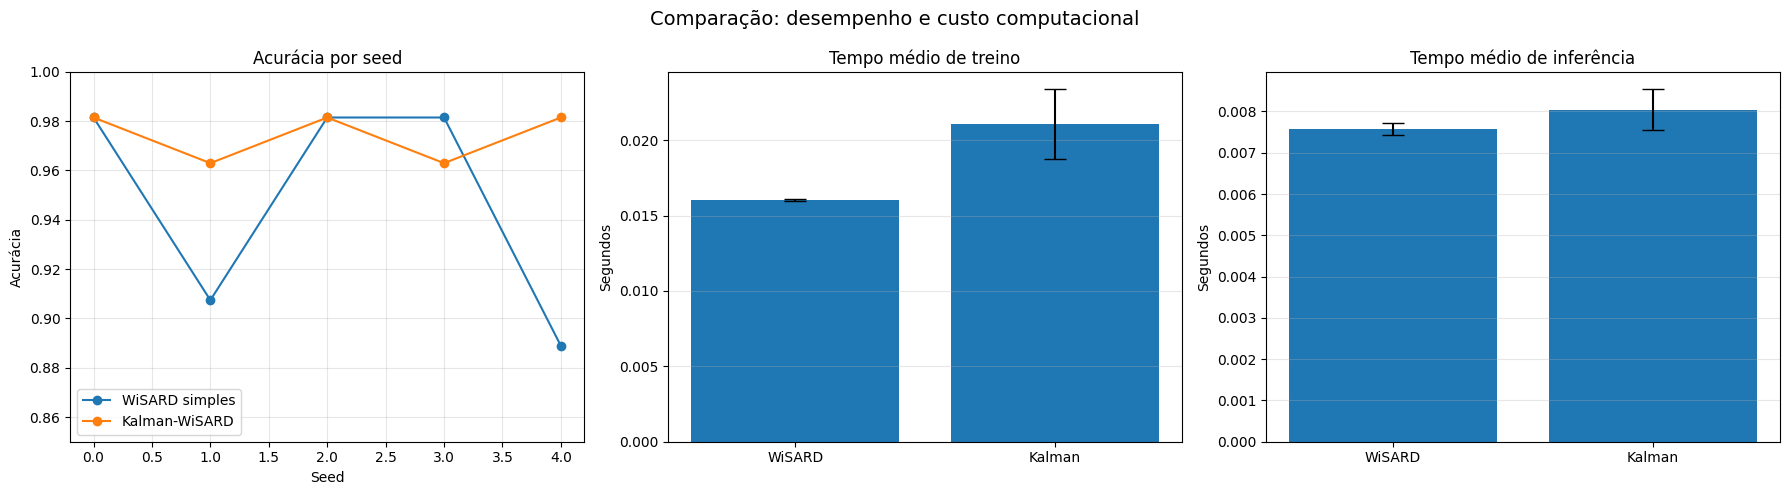

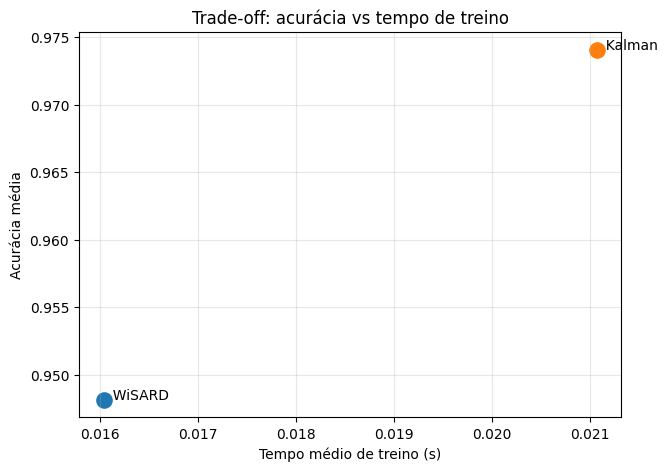

In [46]:
# ============================================================
# EXPERIMENTO COMPLETO EM UM CLICK
# WiSARD simples vs Kalman-WiSARD
# Inclui:
# - acurácia
# - desvio-padrão
# - tempo de treino
# - tempo de inferência
# - gráficos
# ============================================================

# Importa NumPy para operações numéricas.
import numpy as np

# Importa pandas para organizar resultados em tabela.
import pandas as pd

# Importa time para medir tempo de execução.
import time

# Importa defaultdict para dicionários com valores padrão.
from collections import defaultdict

# Importa ferramentas de avaliação e divisão de dados.
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine

# Importa matplotlib para gráficos.
import matplotlib.pyplot as plt


# ============================================================
# ENCODER: THERMOMETER ENCODING
# ============================================================

class ThermometerEncoder:
    # Inicializa o encoder com mínimo, máximo e resolução.
    def __init__(self, minimum, maximum, resolution):
        # Guarda o mínimo do atributo.
        self.minimum = minimum
        
        # Guarda o máximo do atributo.
        self.maximum = maximum
        
        # Guarda quantos bits serão usados.
        self.resolution = resolution
        
        # Calcula o intervalo do atributo e adiciona epsilon para evitar divisão por zero.
        self.range = (maximum - minimum) + 1e-9

    # Codifica um valor real em um vetor thermometer.
    def encode_value(self, value):
        # Limita o valor ao intervalo conhecido.
        value = np.clip(value, self.minimum, self.maximum)
        
        # Normaliza para o intervalo [0, 1].
        normalized = (value - self.minimum) / self.range
        
        # Converte o valor normalizado em quantidade de bits ligados.
        k = int(normalized * self.resolution)
        
        # Garante que k esteja entre 0 e resolution.
        k = min(max(k, 0), self.resolution)
        
        # Cria um vetor de zeros.
        bits = np.zeros(self.resolution, dtype=np.uint8)
        
        # Liga os primeiros k bits.
        bits[:k] = 1
        
        # Retorna o vetor binário.
        return bits


# ============================================================
# CLASSE BASE COM LÓGICA COMPARTILHADA
# ============================================================

class BaseWiSARD:
    # Inicializa os parâmetros estruturais da arquitetura.
    def __init__(self, address_size=4, resolution=16, seed=42):
        # Guarda o tamanho do endereço de cada RAM.
        self.address_size = address_size
        
        # Guarda a resolução do thermometer encoding.
        self.resolution = resolution
        
        # Guarda a seed aleatória.
        self.seed = seed
        
        # Cria um gerador aleatório.
        self.rng = np.random.default_rng(self.seed)
        
        # Inicializa atributos que serão preenchidos no fit.
        self.classes_ = None
        self.encoders_ = None
        self.mapping_ = None
        self.n_rams_ = None
        self.n_bits_ = None

    # Ajusta um encoder para cada atributo do conjunto.
    def _fit_encoders(self, X):
        # Calcula mínimos por coluna.
        mins = X.min(axis=0)
        
        # Calcula máximos por coluna.
        maxs = X.max(axis=0)
        
        # Cria um encoder por atributo.
        self.encoders_ = [
            ThermometerEncoder(mins[j], maxs[j], self.resolution)
            for j in range(X.shape[1])
        ]

    # Codifica uma única amostra em vetor binário.
    def _encode_sample(self, sample):
        # Cria lista para guardar blocos binários de cada atributo.
        encoded_parts = []
        
        # Percorre cada atributo da amostra.
        for j, value in enumerate(sample):
            # Codifica o valor do atributo j.
            encoded_value = self.encoders_[j].encode_value(value)
            
            # Adiciona o bloco à lista.
            encoded_parts.append(encoded_value)
        
        # Concatena todos os blocos em um único vetor.
        return np.concatenate(encoded_parts)

    # Codifica o dataset inteiro.
    def _encode_dataset(self, X):
        # Codifica amostra por amostra e empilha os resultados.
        return np.array([self._encode_sample(sample) for sample in X], dtype=np.uint8)

    # Constrói o mapeamento de bits para RAMs.
    def _build_mapping(self, n_bits):
        # Guarda a quantidade total de bits.
        self.n_bits_ = n_bits
        
        # Calcula quantas RAMs serão necessárias.
        self.n_rams_ = int(np.ceil(n_bits / self.address_size))
        
        # Calcula o total de posições considerando padding.
        total_positions = self.n_rams_ * self.address_size
        
        # Cria os índices reais dos bits.
        indices = np.arange(n_bits)
        
        # Calcula quantos índices extras serão necessários.
        extra = total_positions - n_bits
        
        # Se precisar de padding.
        if extra > 0:
            # Sorteia índices extras com reposição.
            extra_indices = self.rng.choice(indices, size=extra, replace=True)
            
            # Concatena índices reais e extras.
            indices = np.concatenate([indices, extra_indices])
        
        # Embaralha os índices.
        self.rng.shuffle(indices)
        
        # Reorganiza em formato de matriz: RAMs x address_size.
        self.mapping_ = indices.reshape(self.n_rams_, self.address_size)

    # Converte um pequeno vetor de bits em endereço inteiro.
    def _bits_to_address(self, bits):
        # Inicializa endereço.
        address = 0
        
        # Percorre cada bit.
        for bit in bits:
            # Desloca à esquerda e incorpora o bit atual.
            address = (address << 1) | int(bit)
        
        # Retorna o endereço final.
        return address

    # Obtém todos os endereços ativados pelas RAMs.
    def _get_addresses(self, encoded_sample):
        # Cria lista para os endereços.
        addresses = []
        
        # Percorre cada RAM.
        for ram_idx in range(self.n_rams_):
            # Recupera os índices de bits associados à RAM.
            bit_indices = self.mapping_[ram_idx]
            
            # Seleciona os bits correspondentes.
            selected_bits = encoded_sample[bit_indices]
            
            # Converte os bits em endereço.
            address = self._bits_to_address(selected_bits)
            
            # Adiciona o endereço à lista.
            addresses.append(address)
        
        # Retorna a lista completa.
        return addresses


# ============================================================
# BASELINE: WISARD SIMPLES POR CONTAGEM
# ============================================================

class SimpleWiSARD(BaseWiSARD):
    # Inicializa a WiSARD simples.
    def __init__(self, address_size=4, resolution=16, seed=42, use_negative_update=False):
        # Inicializa a classe base.
        super().__init__(address_size=address_size, resolution=resolution, seed=seed)
        
        # Guarda se haverá atualização negativa.
        self.use_negative_update = use_negative_update
        
        # Inicializa a memória.
        self.memory_ = None

    # Treina a WiSARD simples.
    def fit(self, X, y):
        # Converte entradas para arrays NumPy.
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        
        # Descobre as classes.
        self.classes_ = np.unique(y)
        
        # Ajusta os encoders.
        self._fit_encoders(X)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Constrói o mapeamento.
        self._build_mapping(Xb.shape[1])
        
        # Inicializa a memória por classe e por RAM.
        self.memory_ = {
            c: [defaultdict(float) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Percorre as amostras de treino.
        for i in range(len(Xb)):
            # Recupera a amostra binária.
            xb = Xb[i]
            
            # Recupera a classe correta.
            y_true = y[i]
            
            # Obtém os endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Atualização positiva na classe correta.
            for ram_idx, address in enumerate(addresses):
                self.memory_[y_true][ram_idx][address] += 1.0
            
            # Se atualização negativa estiver ativada.
            if self.use_negative_update:
                # Percorre as demais classes.
                for other_class in self.classes_:
                    # Ignora a classe correta.
                    if other_class == y_true:
                        continue
                    
                    # Decrementa as posições ativadas nas classes incorretas.
                    for ram_idx, address in enumerate(addresses):
                        self.memory_[other_class][ram_idx][address] -= 1.0
        
        # Retorna o próprio modelo.
        return self

    # Prediz classes para um conjunto de amostras.
    def predict(self, X):
        # Converte X para NumPy.
        X = np.asarray(X, dtype=float)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Cria lista para predições.
        predictions = []
        
        # Percorre cada amostra binária.
        for xb in Xb:
            # Obtém os endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Inicializa scores por classe.
            scores = {}
            
            # Percorre cada classe.
            for c in self.classes_:
                # Inicializa score.
                score = 0.0
                
                # Soma as contagens das posições ativadas.
                for ram_idx, address in enumerate(addresses):
                    score += self.memory_[c][ram_idx][address]
                
                # Guarda score da classe.
                scores[c] = score
            
            # Seleciona a classe de maior score.
            pred = max(scores, key=scores.get)
            
            # Armazena a predição.
            predictions.append(pred)
        
        # Retorna predições.
        return np.array(predictions)


# ============================================================
# MODELO PROPOSTO: KALMAN-WISARD
# ============================================================

class KalmanWiSARD(BaseWiSARD):
    # Inicializa a Kalman-WiSARD.
    def __init__(
        self,
        address_size=4,
        resolution=16,
        q=1e-3,
        r=5e-2,
        p0=1.0,
        n_epochs=1,
        seed=42,
        use_negative_update=False
    ):
        # Inicializa a classe base.
        super().__init__(address_size=address_size, resolution=resolution, seed=seed)
        
        # Guarda parâmetros do filtro de Kalman.
        self.q = q
        self.r = r
        self.p0 = p0
        self.n_epochs = n_epochs
        self.use_negative_update = use_negative_update
        
        # Inicializa memórias.
        self.memory_x_ = None
        self.memory_p_ = None

    # Atualização escalar do filtro de Kalman.
    def _kalman_update(self, current_x, current_p, z):
        # Predição do estado.
        x_pred = current_x
        
        # Predição da incerteza.
        p_pred = current_p + self.q
        
        # Cálculo do ganho de Kalman.
        k_gain = p_pred / (p_pred + self.r)
        
        # Atualização do estado.
        updated_x = x_pred + k_gain * (z - x_pred)
        
        # Atualização da incerteza.
        updated_p = (1.0 - k_gain) * p_pred
        
        # Retorna estado e incerteza atualizados.
        return updated_x, updated_p

    # Treina a Kalman-WiSARD.
    def fit(self, X, y):
        # Converte entradas para arrays NumPy.
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        
        # Descobre as classes.
        self.classes_ = np.unique(y)
        
        # Ajusta os encoders.
        self._fit_encoders(X)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Constrói o mapeamento.
        self._build_mapping(Xb.shape[1])
        
        # Inicializa memória de estados.
        self.memory_x_ = {
            c: [defaultdict(float) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Inicializa memória de incertezas.
        self.memory_p_ = {
            c: [defaultdict(lambda: self.p0) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Repete por várias épocas.
        for epoch in range(self.n_epochs):
            # Embaralha a ordem das amostras.
            indices = self.rng.permutation(len(Xb))
            
            # Percorre as amostras embaralhadas.
            for idx in indices:
                # Recupera amostra binária e classe correta.
                xb = Xb[idx]
                y_true = y[idx]
                
                # Obtém os endereços ativados.
                addresses = self._get_addresses(xb)
                
                # Atualização positiva na classe correta.
                for ram_idx, address in enumerate(addresses):
                    # Lê estado e incerteza atuais.
                    current_x = self.memory_x_[y_true][ram_idx][address]
                    current_p = self.memory_p_[y_true][ram_idx][address]
                    
                    # Define observação positiva.
                    z = 1.0
                    
                    # Atualiza via Kalman.
                    new_x, new_p = self._kalman_update(current_x, current_p, z)
                    
                    # Salva estado e incerteza.
                    self.memory_x_[y_true][ram_idx][address] = new_x
                    self.memory_p_[y_true][ram_idx][address] = new_p
                
                # Se atualização negativa estiver ativada.
                if self.use_negative_update:
                    # Percorre as classes incorretas.
                    for other_class in self.classes_:
                        # Ignora a classe correta.
                        if other_class == y_true:
                            continue
                        
                        # Atualiza as classes incorretas com z = 0.
                        for ram_idx, address in enumerate(addresses):
                            # Lê estado e incerteza atuais.
                            current_x = self.memory_x_[other_class][ram_idx][address]
                            current_p = self.memory_p_[other_class][ram_idx][address]
                            
                            # Define observação negativa.
                            z = 0.0
                            
                            # Atualiza via Kalman.
                            new_x, new_p = self._kalman_update(current_x, current_p, z)
                            
                            # Salva estado e incerteza.
                            self.memory_x_[other_class][ram_idx][address] = new_x
                            self.memory_p_[other_class][ram_idx][address] = new_p
        
        # Retorna o modelo.
        return self

    # Prediz classes para um conjunto.
    def predict(self, X):
        # Converte X para NumPy.
        X = np.asarray(X, dtype=float)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Cria lista para predições.
        predictions = []
        
        # Percorre cada amostra binária.
        for xb in Xb:
            # Obtém os endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Inicializa scores.
            scores = {}
            
            # Percorre cada classe.
            for c in self.classes_:
                # Inicializa score.
                score = 0.0
                
                # Soma os estados armazenados.
                for ram_idx, address in enumerate(addresses):
                    score += self.memory_x_[c][ram_idx][address]
                
                # Guarda o score.
                scores[c] = score
            
            # Seleciona a classe com maior score.
            pred = max(scores, key=scores.get)
            
            # Armazena a predição.
            predictions.append(pred)
        
        # Retorna as predições.
        return np.array(predictions)


# ============================================================
# FUNÇÃO DE AVALIAÇÃO COM CUSTO COMPUTACIONAL
# ============================================================

def evaluate_model_with_cost(model_class, model_params, X, y, seeds=(0, 1, 2, 3, 4)):
    # Cria listas para armazenar resultados.
    accuracies = []
    train_times = []
    test_times = []
    
    # Percorre cada seed.
    for seed in seeds:
        # Divide dados em treino e teste.
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.30,
            random_state=seed,
            stratify=y
        )
        
        # Instancia o modelo.
        model = model_class(seed=seed, **model_params)
        
        # Mede tempo de treino.
        start_train = time.time()
        model.fit(X_train, y_train)
        end_train = time.time()
        
        # Guarda o tempo de treino.
        train_times.append(end_train - start_train)
        
        # Mede tempo de inferência.
        start_test = time.time()
        y_pred = model.predict(X_test)
        end_test = time.time()
        
        # Guarda o tempo de inferência.
        test_times.append(end_test - start_test)
        
        # Calcula a acurácia.
        acc = accuracy_score(y_test, y_pred)
        
        # Guarda a acurácia.
        accuracies.append(acc)
    
    # Retorna todas as estatísticas resumidas.
    return {
        "mean_accuracy": float(np.mean(accuracies)),
        "std_accuracy": float(np.std(accuracies)),
        "mean_train_time_sec": float(np.mean(train_times)),
        "std_train_time_sec": float(np.std(train_times)),
        "mean_test_time_sec": float(np.mean(test_times)),
        "std_test_time_sec": float(np.std(test_times)),
        "all_accuracies": accuracies,
        "all_train_times": train_times,
        "all_test_times": test_times,
    }


# ============================================================
# CARREGAMENTO DOS DADOS
# ============================================================

# Carrega o dataset Wine.
data = load_wine()

# Extrai atributos.
X = data.data

# Extrai rótulos.
y = data.target


# ============================================================
# PARÂMETROS DOS MODELOS
# ============================================================

# Define a melhor configuração encontrada para a Kalman-WiSARD.
best_kalman_params = {
    "address_size": 4,
    "resolution": 16,
    "q": 1e-3,
    "r": 5e-2,
    "p0": 1.0,
    "n_epochs": 1,
    "use_negative_update": False
}

# Define o baseline simples com a mesma estrutura.
baseline_params = {
    "address_size": 4,
    "resolution": 16,
    "use_negative_update": False
}

# Define as seeds do experimento.
seeds = (0, 1, 2, 3, 4)


# ============================================================
# EXECUÇÃO DOS EXPERIMENTOS
# ============================================================

# Avalia o baseline.
baseline_results = evaluate_model_with_cost(
    model_class=SimpleWiSARD,
    model_params=baseline_params,
    X=X,
    y=y,
    seeds=seeds
)

# Avalia a Kalman-WiSARD.
kalman_results = evaluate_model_with_cost(
    model_class=KalmanWiSARD,
    model_params=best_kalman_params,
    X=X,
    y=y,
    seeds=seeds
)


# ============================================================
# TABELA FINAL
# ============================================================

# Cria DataFrame comparativo.
comparison_df = pd.DataFrame([
    {
        "modelo": "WiSARD simples",
        "address_size": baseline_params["address_size"],
        "resolution": baseline_params["resolution"],
        "q": np.nan,
        "r": np.nan,
        "n_epochs": 1,
        "use_negative_update": baseline_params["use_negative_update"],
        **baseline_results
    },
    {
        "modelo": "Kalman-WiSARD",
        "address_size": best_kalman_params["address_size"],
        "resolution": best_kalman_params["resolution"],
        "q": best_kalman_params["q"],
        "r": best_kalman_params["r"],
        "n_epochs": best_kalman_params["n_epochs"],
        "use_negative_update": best_kalman_params["use_negative_update"],
        **kalman_results
    }
])

# Ordena por melhor acurácia média.
comparison_df = comparison_df.sort_values(
    by=["mean_accuracy", "std_accuracy"],
    ascending=[False, True]
).reset_index(drop=True)

# Imprime a tabela final.
print("===== COMPARAÇÃO FINAL =====")
print(comparison_df[[
    "modelo",
    "address_size",
    "resolution",
    "q",
    "r",
    "n_epochs",
    "use_negative_update",
    "mean_accuracy",
    "std_accuracy",
    "mean_train_time_sec",
    "mean_test_time_sec"
]])

# Calcula ganho de acurácia do Kalman sobre baseline.
acc_gain = kalman_results["mean_accuracy"] - baseline_results["mean_accuracy"]

# Calcula razão de tempo de treino.
train_time_ratio = (
    kalman_results["mean_train_time_sec"] / baseline_results["mean_train_time_sec"]
    if baseline_results["mean_train_time_sec"] > 0 else np.nan
)

# Calcula razão de tempo de inferência.
test_time_ratio = (
    kalman_results["mean_test_time_sec"] / baseline_results["mean_test_time_sec"]
    if baseline_results["mean_test_time_sec"] > 0 else np.nan
)

# Imprime resumos numéricos.
print("\n===== RESUMO =====")
print(f"Ganho médio de acurácia (Kalman - baseline): {acc_gain:.6f}")
print(f"Razão de tempo de treino (Kalman / baseline): {train_time_ratio:.3f}x")
print(f"Razão de tempo de inferência (Kalman / baseline): {test_time_ratio:.3f}x")

# Imprime listas detalhadas.
print("\nAcurácias WiSARD simples:", baseline_results["all_accuracies"])
print("Acurácias Kalman-WiSARD:", kalman_results["all_accuracies"])

print("\nTempos de treino WiSARD simples (s):", baseline_results["all_train_times"])
print("Tempos de treino Kalman-WiSARD (s):", kalman_results["all_train_times"])

print("\nTempos de inferência WiSARD simples (s):", baseline_results["all_test_times"])
print("Tempos de inferência Kalman-WiSARD (s):", kalman_results["all_test_times"])


# ============================================================
# GRÁFICOS
# ============================================================

# Recupera vetores para os gráficos.
baseline_accs = baseline_results["all_accuracies"]
kalman_accs = kalman_results["all_accuracies"]

baseline_train = baseline_results["all_train_times"]
kalman_train = kalman_results["all_train_times"]

baseline_test = baseline_results["all_test_times"]
kalman_test = kalman_results["all_test_times"]

# Converte seeds para array para usar no eixo x.
seed_axis = np.arange(len(seeds))

# Cria figura com 3 gráficos lado a lado.
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# ------------------------------------------------------------
# GRÁFICO 1: ACURÁCIA POR SEED
# ------------------------------------------------------------

# Plota baseline.
axes[0].plot(seed_axis, baseline_accs, marker="o", label="WiSARD simples")

# Plota Kalman.
axes[0].plot(seed_axis, kalman_accs, marker="o", label="Kalman-WiSARD")

# Define título.
axes[0].set_title("Acurácia por seed")

# Define rótulos dos eixos.
axes[0].set_xlabel("Seed")
axes[0].set_ylabel("Acurácia")

# Define limite do eixo y.
axes[0].set_ylim(0.85, 1.0)

# Adiciona grade.
axes[0].grid(alpha=0.3)

# Mostra legenda.
axes[0].legend()

# ------------------------------------------------------------
# GRÁFICO 2: TEMPO DE TREINO
# ------------------------------------------------------------

# Calcula médias de treino.
train_means = [np.mean(baseline_train), np.mean(kalman_train)]

# Calcula desvios de treino.
train_stds = [np.std(baseline_train), np.std(kalman_train)]

# Plota barras com erro.
axes[1].bar(["WiSARD", "Kalman"], train_means, yerr=train_stds, capsize=8)

# Define título.
axes[1].set_title("Tempo médio de treino")

# Define eixo y.
axes[1].set_ylabel("Segundos")

# Adiciona grade.
axes[1].grid(axis="y", alpha=0.3)

# ------------------------------------------------------------
# GRÁFICO 3: TEMPO DE INFERÊNCIA
# ------------------------------------------------------------

# Calcula médias de teste.
test_means = [np.mean(baseline_test), np.mean(kalman_test)]

# Calcula desvios de teste.
test_stds = [np.std(baseline_test), np.std(kalman_test)]

# Plota barras com erro.
axes[2].bar(["WiSARD", "Kalman"], test_means, yerr=test_stds, capsize=8)

# Define título.
axes[2].set_title("Tempo médio de inferência")

# Define eixo y.
axes[2].set_ylabel("Segundos")

# Adiciona grade.
axes[2].grid(axis="y", alpha=0.3)

# Define título geral.
plt.suptitle("Comparação: desempenho e custo computacional", fontsize=14)

# Ajusta layout.
plt.tight_layout()

# Exibe os gráficos.
plt.show()


# ============================================================
# GRÁFICO EXTRA: TRADE-OFF ACURÁCIA VS TEMPO DE TREINO
# ============================================================

# Cria nova figura.
plt.figure(figsize=(7, 5))

# Plota o ponto do baseline.
plt.scatter(
    baseline_results["mean_train_time_sec"],
    baseline_results["mean_accuracy"],
    s=120,
    label="WiSARD simples"
)

# Plota o ponto do Kalman.
plt.scatter(
    kalman_results["mean_train_time_sec"],
    kalman_results["mean_accuracy"],
    s=120,
    label="Kalman-WiSARD"
)

# Escreve o nome ao lado do ponto do baseline.
plt.text(
    baseline_results["mean_train_time_sec"],
    baseline_results["mean_accuracy"],
    "  WiSARD"
)

# Escreve o nome ao lado do ponto do Kalman.
plt.text(
    kalman_results["mean_train_time_sec"],
    kalman_results["mean_accuracy"],
    "  Kalman"
)

# Define título.
plt.title("Trade-off: acurácia vs tempo de treino")

# Define rótulos dos eixos.
plt.xlabel("Tempo médio de treino (s)")
plt.ylabel("Acurácia média")

# Adiciona grade.
plt.grid(alpha=0.3)

# Exibe o gráfico.
plt.show()

===== COMPARAÇÃO FINAL =====
           modelo  mean_accuracy  std_accuracy  mean_train_wall_sec  \
0   Kalman-WiSARD       0.974074      0.009072             0.018393   
1  WiSARD simples       0.948148      0.041243             0.017203   

   mean_test_wall_sec  mean_train_cpu_sec  mean_test_cpu_sec  \
0            0.009062               0.020              0.008   
1            0.008704               0.014              0.008   

   mean_train_peak_rss_mb  mean_test_peak_rss_mb  mean_train_energy_j  \
0              275.925781             275.925781                  NaN   
1              275.925781             275.925781                  NaN   

   mean_test_energy_j  rapl_available  
0                 NaN           False  
1                 NaN           False  

===== RESUMO =====
Ganho médio de acurácia (Kalman - baseline): 0.025926
Razão de tempo real de treino (Kalman / baseline): 1.069x
Razão de tempo real de inferência (Kalman / baseline): 1.041x
Razão de tempo de CPU no trein

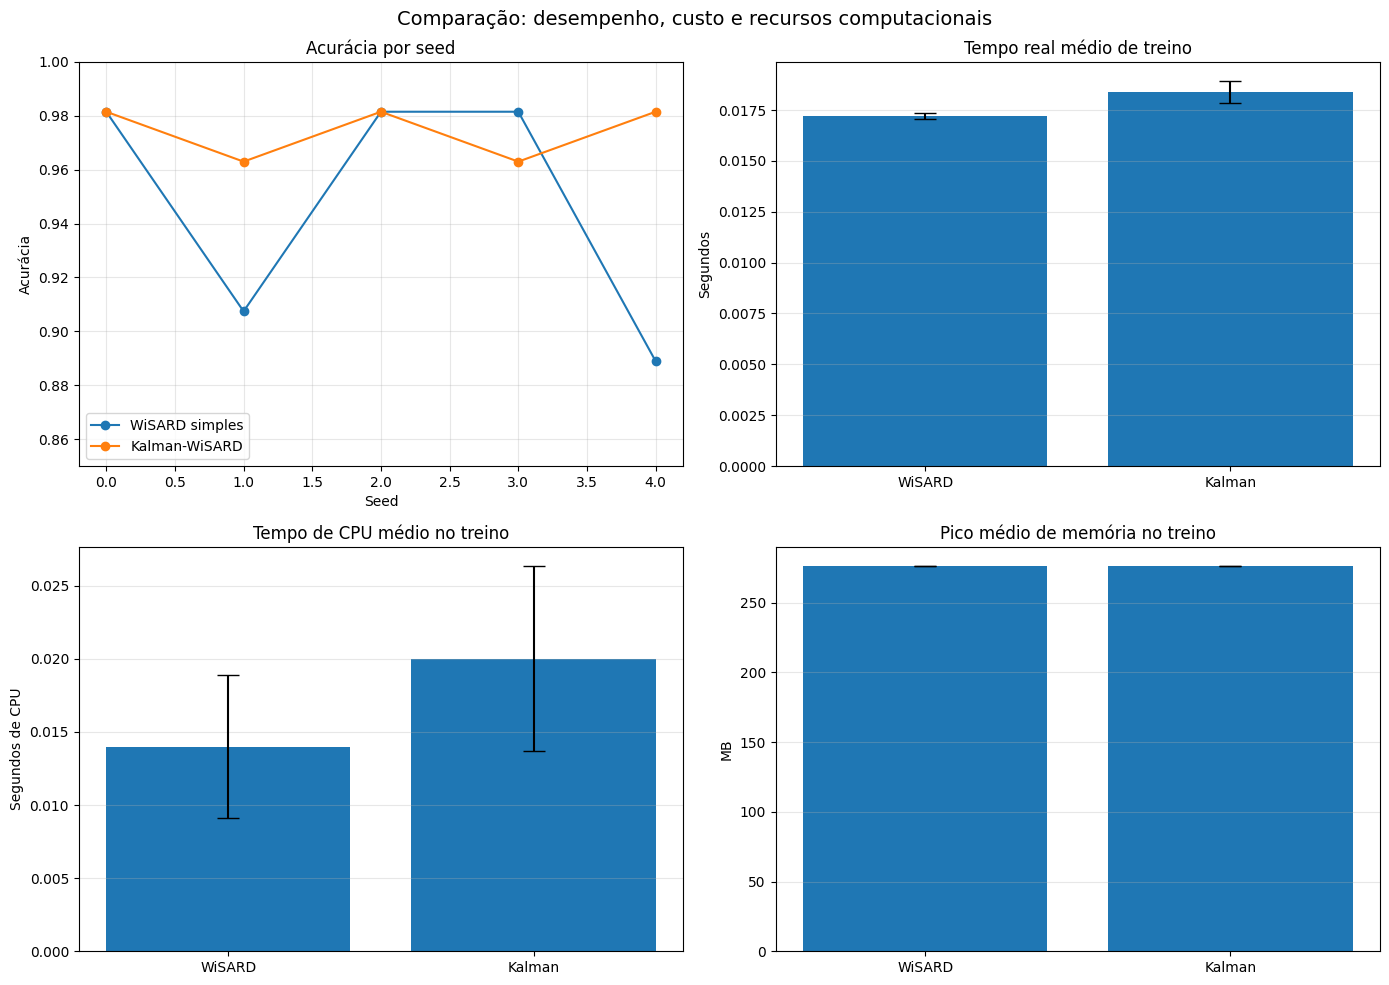

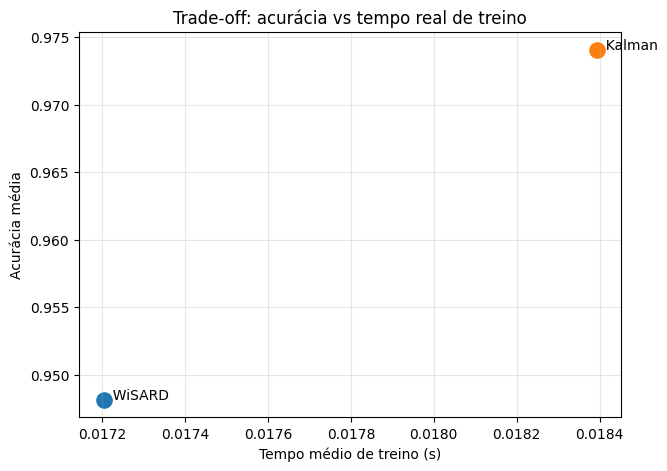

In [47]:
# ============================================================
# EXPERIMENTO COMPLETO EM UM CLICK
# WiSARD simples vs Kalman-WiSARD
# Mede:
# - acurácia
# - estabilidade
# - tempo real
# - tempo de CPU
# - pico de memória
# - energia via Intel RAPL (se disponível no Linux)
# ============================================================

# ============================================================
# IMPORTAÇÕES
# ============================================================

# Importa NumPy para operações numéricas.
import numpy as np

# Importa pandas para organizar os resultados em tabelas.
import pandas as pd

# Importa time para medir tempo real.
import time

# Importa os para lidar com caminhos e PID do processo.
import os

# Importa glob para localizar arquivos do RAPL.
import glob

# Importa threading para monitorar memória em paralelo.
import threading

# Importa psutil para medir CPU e memória do processo.
import psutil

# Importa defaultdict para construir memórias esparsas.
from collections import defaultdict

# Importa utilitários do scikit-learn.
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.datasets import load_wine

# Importa matplotlib para gráficos.
import matplotlib.pyplot as plt


# ============================================================
# UTILITÁRIOS DE ENERGIA (RAPL)
# ============================================================

def find_rapl_energy_file():
    # Procura arquivos de energia do Intel RAPL expostos pelo Linux.
    
    # Define padrões possíveis de caminhos no sysfs.
    candidate_patterns = [
        "/sys/class/powercap/intel-rapl*/energy_uj",
        "/sys/class/powercap/intel-rapl:*/*/energy_uj",
        "/sys/class/powercap/intel-rapl:*/energy_uj",
    ]
    
    # Cria lista para acumular arquivos candidatos.
    candidates = []
    
    # Percorre cada padrão.
    for pattern in candidate_patterns:
        # Adiciona todos os arquivos encontrados para o padrão.
        candidates.extend(glob.glob(pattern))
    
    # Remove duplicatas e ordena.
    candidates = sorted(set(candidates))
    
    # Se encontrou algum candidato, retorna o primeiro.
    if candidates:
        return candidates[0]
    
    # Se não encontrou nada, retorna None.
    return None


def read_rapl_energy_uj(energy_file):
    # Lê energia acumulada em microjoules a partir do arquivo do RAPL.
    
    # Se o arquivo não existir, retorna None.
    if energy_file is None:
        return None
    
    try:
        # Abre o arquivo e lê o valor inteiro.
        with open(energy_file, "r") as f:
            value = int(f.read().strip())
        
        # Retorna o valor lido.
        return value
    except Exception:
        # Se não conseguir ler, retorna None.
        return None


def read_rapl_max_range_uj(energy_file):
    # Lê o alcance máximo do contador para tratar wrap-around.
    
    # Se o arquivo não existir, retorna None.
    if energy_file is None:
        return None
    
    try:
        # Monta o caminho do arquivo de alcance máximo.
        max_file = os.path.join(os.path.dirname(energy_file), "max_energy_range_uj")
        
        # Abre e lê o valor.
        with open(max_file, "r") as f:
            value = int(f.read().strip())
        
        # Retorna o valor lido.
        return value
    except Exception:
        # Se não conseguir ler, retorna None.
        return None


def compute_energy_joules(start_uj, end_uj, max_range_uj=None):
    # Converte duas leituras acumuladas do RAPL em energia consumida em joules.
    
    # Se alguma leitura for inválida, retorna None.
    if start_uj is None or end_uj is None:
        return None
    
    # Se não houve wrap-around.
    if end_uj >= start_uj:
        delta_uj = end_uj - start_uj
    else:
        # Se houve wrap-around e há alcance máximo conhecido.
        if max_range_uj is not None:
            delta_uj = (max_range_uj - start_uj) + end_uj
        else:
            # Se não há como tratar, retorna None.
            return None
    
    # Converte microjoules para joules.
    return delta_uj / 1e6


# ============================================================
# MONITOR DE MEMÓRIA
# ============================================================

class PeakMemoryMonitor:
    # Monitora o pico de RSS do processo durante um trecho de execução.
    def __init__(self, interval_sec=0.001):
        # Guarda o intervalo entre amostras.
        self.interval_sec = interval_sec
        
        # Guarda a flag de execução.
        self._running = False
        
        # Guarda a thread de monitoramento.
        self._thread = None
        
        # Guarda o pico observado.
        self.peak_rss_bytes = 0
        
        # Obtém o processo atual.
        self.process = psutil.Process(os.getpid())

    def _worker(self):
        # Loop interno que amostra o uso de memória periodicamente.
        while self._running:
            try:
                # Lê a memória residente atual.
                rss = self.process.memory_info().rss
                
                # Atualiza o pico se necessário.
                if rss > self.peak_rss_bytes:
                    self.peak_rss_bytes = rss
            except Exception:
                # Ignora erros transitórios.
                pass
            
            # Aguarda o próximo instante de amostragem.
            time.sleep(self.interval_sec)

    def start(self):
        # Inicia o monitoramento.
        
        # Reseta o pico.
        self.peak_rss_bytes = 0
        
        # Liga a flag.
        self._running = True
        
        # Cria a thread.
        self._thread = threading.Thread(target=self._worker, daemon=True)
        
        # Inicia a thread.
        self._thread.start()

    def stop(self):
        # Para o monitoramento.
        
        # Desliga a flag.
        self._running = False
        
        # Aguarda o encerramento da thread.
        if self._thread is not None:
            self._thread.join(timeout=1.0)


# ============================================================
# ENCODER
# ============================================================

class ThermometerEncoder:
    # Inicializa o encoder.
    def __init__(self, minimum, maximum, resolution):
        # Guarda o mínimo do atributo.
        self.minimum = minimum
        
        # Guarda o máximo do atributo.
        self.maximum = maximum
        
        # Guarda a resolução.
        self.resolution = resolution
        
        # Calcula o intervalo.
        self.range = (maximum - minimum) + 1e-9

    def encode_value(self, value):
        # Codifica um valor real em thermometer encoding.
        
        # Faz clipping para o intervalo observado.
        value = np.clip(value, self.minimum, self.maximum)
        
        # Normaliza no intervalo [0, 1].
        normalized = (value - self.minimum) / self.range
        
        # Converte para quantidade de bits ligados.
        k = int(normalized * self.resolution)
        
        # Garante limites válidos.
        k = min(max(k, 0), self.resolution)
        
        # Cria vetor de zeros.
        bits = np.zeros(self.resolution, dtype=np.uint8)
        
        # Liga os primeiros k bits.
        bits[:k] = 1
        
        # Retorna o vetor binário.
        return bits


# ============================================================
# CLASSE BASE
# ============================================================

class BaseWiSARD:
    # Inicializa a estrutura base da WiSARD.
    def __init__(self, address_size=4, resolution=16, seed=42):
        # Guarda o tamanho do endereço.
        self.address_size = address_size
        
        # Guarda a resolução do encoding.
        self.resolution = resolution
        
        # Guarda a seed.
        self.seed = seed
        
        # Cria o gerador aleatório.
        self.rng = np.random.default_rng(self.seed)
        
        # Inicializa atributos que serão definidos depois.
        self.classes_ = None
        self.encoders_ = None
        self.mapping_ = None
        self.n_rams_ = None
        self.n_bits_ = None

    def _fit_encoders(self, X):
        # Ajusta um encoder por atributo.
        
        # Calcula mínimos por coluna.
        mins = X.min(axis=0)
        
        # Calcula máximos por coluna.
        maxs = X.max(axis=0)
        
        # Cria os encoders atributo a atributo.
        self.encoders_ = [
            ThermometerEncoder(mins[j], maxs[j], self.resolution)
            for j in range(X.shape[1])
        ]

    def _encode_sample(self, sample):
        # Codifica uma única amostra.
        
        # Cria lista para armazenar os blocos binários.
        encoded_parts = []
        
        # Percorre cada atributo.
        for j, value in enumerate(sample):
            # Codifica o valor do atributo.
            encoded_value = self.encoders_[j].encode_value(value)
            
            # Adiciona o bloco codificado.
            encoded_parts.append(encoded_value)
        
        # Concatena os blocos.
        return np.concatenate(encoded_parts)

    def _encode_dataset(self, X):
        # Codifica um conjunto inteiro.
        return np.array([self._encode_sample(sample) for sample in X], dtype=np.uint8)

    def _build_mapping(self, n_bits):
        # Constrói o mapeamento aleatório de bits para RAMs.
        
        # Guarda a quantidade de bits.
        self.n_bits_ = n_bits
        
        # Calcula o número de RAMs.
        self.n_rams_ = int(np.ceil(n_bits / self.address_size))
        
        # Calcula total com padding.
        total_positions = self.n_rams_ * self.address_size
        
        # Cria índices reais.
        indices = np.arange(n_bits)
        
        # Calcula quantos índices extras faltam.
        extra = total_positions - n_bits
        
        # Se faltar espaço, adiciona padding por repetição.
        if extra > 0:
            extra_indices = self.rng.choice(indices, size=extra, replace=True)
            indices = np.concatenate([indices, extra_indices])
        
        # Embaralha os índices.
        self.rng.shuffle(indices)
        
        # Reorganiza em matriz.
        self.mapping_ = indices.reshape(self.n_rams_, self.address_size)

    def _bits_to_address(self, bits):
        # Converte vetor de bits em inteiro.
        
        # Inicializa o endereço.
        address = 0
        
        # Percorre os bits.
        for bit in bits:
            # Desloca à esquerda e incorpora o bit.
            address = (address << 1) | int(bit)
        
        # Retorna o endereço.
        return address

    def _get_addresses(self, encoded_sample):
        # Obtém os endereços ativados por uma amostra codificada.
        
        # Cria lista para armazenar os endereços.
        addresses = []
        
        # Percorre cada RAM.
        for ram_idx in range(self.n_rams_):
            # Recupera os índices de bits da RAM.
            bit_indices = self.mapping_[ram_idx]
            
            # Seleciona os bits correspondentes.
            selected_bits = encoded_sample[bit_indices]
            
            # Converte em endereço.
            address = self._bits_to_address(selected_bits)
            
            # Adiciona o endereço à lista.
            addresses.append(address)
        
        # Retorna a lista de endereços.
        return addresses


# ============================================================
# WISARD SIMPLES
# ============================================================

class SimpleWiSARD(BaseWiSARD):
    # Inicializa a WiSARD simples.
    def __init__(self, address_size=4, resolution=16, seed=42, use_negative_update=False):
        # Inicializa a classe base.
        super().__init__(address_size=address_size, resolution=resolution, seed=seed)
        
        # Guarda se usa atualização negativa.
        self.use_negative_update = use_negative_update
        
        # Inicializa a memória.
        self.memory_ = None

    def fit(self, X, y):
        # Treina a WiSARD simples.
        
        # Converte entradas.
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        
        # Descobre as classes.
        self.classes_ = np.unique(y)
        
        # Ajusta encoders.
        self._fit_encoders(X)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Constrói o mapeamento.
        self._build_mapping(Xb.shape[1])
        
        # Inicializa a memória por classe e RAM.
        self.memory_ = {
            c: [defaultdict(float) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Percorre as amostras.
        for i in range(len(Xb)):
            # Recupera a amostra binária.
            xb = Xb[i]
            
            # Recupera a classe correta.
            y_true = y[i]
            
            # Obtém endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Atualização positiva.
            for ram_idx, address in enumerate(addresses):
                self.memory_[y_true][ram_idx][address] += 1.0
            
            # Se atualização negativa estiver habilitada.
            if self.use_negative_update:
                for other_class in self.classes_:
                    if other_class == y_true:
                        continue
                    for ram_idx, address in enumerate(addresses):
                        self.memory_[other_class][ram_idx][address] -= 1.0
        
        # Retorna o modelo.
        return self

    def predict(self, X):
        # Prediz as classes.
        
        # Converte as entradas.
        X = np.asarray(X, dtype=float)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Cria lista de predições.
        predictions = []
        
        # Percorre as amostras.
        for xb in Xb:
            # Obtém endereços ativados.
            addresses = self._get_addresses(xb)
            
            # Cria dicionário de scores.
            scores = {}
            
            # Calcula score de cada classe.
            for c in self.classes_:
                score = 0.0
                for ram_idx, address in enumerate(addresses):
                    score += self.memory_[c][ram_idx][address]
                scores[c] = score
            
            # Escolhe a classe de maior score.
            pred = max(scores, key=scores.get)
            
            # Armazena a predição.
            predictions.append(pred)
        
        # Retorna as predições.
        return np.array(predictions)


# ============================================================
# KALMAN-WISARD
# ============================================================

class KalmanWiSARD(BaseWiSARD):
    # Inicializa a Kalman-WiSARD.
    def __init__(
        self,
        address_size=4,
        resolution=16,
        q=1e-3,
        r=5e-2,
        p0=1.0,
        n_epochs=1,
        seed=42,
        use_negative_update=False
    ):
        # Inicializa a classe base.
        super().__init__(address_size=address_size, resolution=resolution, seed=seed)
        
        # Guarda os parâmetros do Kalman.
        self.q = q
        self.r = r
        self.p0 = p0
        self.n_epochs = n_epochs
        self.use_negative_update = use_negative_update
        
        # Inicializa memórias.
        self.memory_x_ = None
        self.memory_p_ = None

    def _kalman_update(self, current_x, current_p, z):
        # Executa a atualização escalar do filtro de Kalman.
        
        # Predição do estado.
        x_pred = current_x
        
        # Predição da incerteza.
        p_pred = current_p + self.q
        
        # Ganho de Kalman.
        k_gain = p_pred / (p_pred + self.r)
        
        # Atualização do estado.
        updated_x = x_pred + k_gain * (z - x_pred)
        
        # Atualização da incerteza.
        updated_p = (1.0 - k_gain) * p_pred
        
        # Retorna o novo estado e a nova incerteza.
        return updated_x, updated_p

    def fit(self, X, y):
        # Treina a Kalman-WiSARD.
        
        # Converte entradas.
        X = np.asarray(X, dtype=float)
        y = np.asarray(y)
        
        # Descobre as classes.
        self.classes_ = np.unique(y)
        
        # Ajusta encoders.
        self._fit_encoders(X)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Constrói o mapeamento.
        self._build_mapping(Xb.shape[1])
        
        # Inicializa memória de estados.
        self.memory_x_ = {
            c: [defaultdict(float) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Inicializa memória de incertezas.
        self.memory_p_ = {
            c: [defaultdict(lambda: self.p0) for _ in range(self.n_rams_)]
            for c in self.classes_
        }
        
        # Repete por várias épocas.
        for epoch in range(self.n_epochs):
            # Embaralha a ordem.
            indices = self.rng.permutation(len(Xb))
            
            # Percorre as amostras.
            for idx in indices:
                xb = Xb[idx]
                y_true = y[idx]
                addresses = self._get_addresses(xb)
                
                # Atualização positiva.
                for ram_idx, address in enumerate(addresses):
                    current_x = self.memory_x_[y_true][ram_idx][address]
                    current_p = self.memory_p_[y_true][ram_idx][address]
                    z = 1.0
                    new_x, new_p = self._kalman_update(current_x, current_p, z)
                    self.memory_x_[y_true][ram_idx][address] = new_x
                    self.memory_p_[y_true][ram_idx][address] = new_p
                
                # Atualização negativa opcional.
                if self.use_negative_update:
                    for other_class in self.classes_:
                        if other_class == y_true:
                            continue
                        for ram_idx, address in enumerate(addresses):
                            current_x = self.memory_x_[other_class][ram_idx][address]
                            current_p = self.memory_p_[other_class][ram_idx][address]
                            z = 0.0
                            new_x, new_p = self._kalman_update(current_x, current_p, z)
                            self.memory_x_[other_class][ram_idx][address] = new_x
                            self.memory_p_[other_class][ram_idx][address] = new_p
        
        # Retorna o modelo.
        return self

    def predict(self, X):
        # Prediz as classes.
        
        # Converte entradas.
        X = np.asarray(X, dtype=float)
        
        # Codifica o conjunto.
        Xb = self._encode_dataset(X)
        
        # Cria lista de predições.
        predictions = []
        
        # Percorre as amostras.
        for xb in Xb:
            addresses = self._get_addresses(xb)
            scores = {}
            
            # Calcula score por classe.
            for c in self.classes_:
                score = 0.0
                for ram_idx, address in enumerate(addresses):
                    score += self.memory_x_[c][ram_idx][address]
                scores[c] = score
            
            # Seleciona a melhor classe.
            pred = max(scores, key=scores.get)
            predictions.append(pred)
        
        # Retorna as predições.
        return np.array(predictions)


# ============================================================
# FUNÇÃO DE AVALIAÇÃO COMPLETA
# ============================================================

def evaluate_model_full(model_class, model_params, X, y, seeds=(0, 1, 2, 3, 4)):
    # Mede acurácia, tempo, CPU, memória e energia para um modelo.
    
    # Cria listas para armazenar os resultados por seed.
    accuracies = []
    train_wall_times = []
    test_wall_times = []
    train_cpu_times = []
    test_cpu_times = []
    train_peak_memories = []
    test_peak_memories = []
    train_energies_j = []
    test_energies_j = []
    
    # Obtém o processo atual.
    process = psutil.Process(os.getpid())
    
    # Procura o arquivo de energia do RAPL.
    rapl_energy_file = find_rapl_energy_file()
    
    # Lê o alcance máximo do contador do RAPL.
    rapl_max_range = read_rapl_max_range_uj(rapl_energy_file)
    
    # Percorre cada seed.
    for seed in seeds:
        # Divide os dados em treino e teste.
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.30,
            random_state=seed,
            stratify=y
        )
        
        # Instancia o modelo.
        model = model_class(seed=seed, **model_params)
        
        # =====================================================
        # TREINO
        # =====================================================
        
        # Cria o monitor de pico de memória para o treino.
        train_mem_monitor = PeakMemoryMonitor(interval_sec=0.001)
        
        # Lê energia antes do treino.
        train_energy_start = read_rapl_energy_uj(rapl_energy_file)
        
        # Lê tempo de CPU antes do treino.
        train_cpu_start = process.cpu_times()
        
        # Lê tempo real antes do treino.
        train_wall_start = time.time()
        
        # Inicia monitoramento de memória.
        train_mem_monitor.start()
        
        # Executa o treino.
        model.fit(X_train, y_train)
        
        # Para o monitoramento de memória.
        train_mem_monitor.stop()
        
        # Lê tempo real após o treino.
        train_wall_end = time.time()
        
        # Lê tempo de CPU após o treino.
        train_cpu_end = process.cpu_times()
        
        # Lê energia após o treino.
        train_energy_end = read_rapl_energy_uj(rapl_energy_file)
        
        # Calcula o tempo real do treino.
        train_wall = train_wall_end - train_wall_start
        
        # Calcula o tempo de CPU do treino.
        train_cpu = (
            (train_cpu_end.user - train_cpu_start.user) +
            (train_cpu_end.system - train_cpu_start.system)
        )
        
        # Calcula a energia do treino em joules.
        train_energy_j = compute_energy_joules(train_energy_start, train_energy_end, rapl_max_range)
        
        # Guarda métricas do treino.
        train_wall_times.append(train_wall)
        train_cpu_times.append(train_cpu)
        train_peak_memories.append(train_mem_monitor.peak_rss_bytes)
        train_energies_j.append(train_energy_j)
        
        # =====================================================
        # INFERÊNCIA
        # =====================================================
        
        # Cria o monitor de memória para inferência.
        test_mem_monitor = PeakMemoryMonitor(interval_sec=0.001)
        
        # Lê energia antes da inferência.
        test_energy_start = read_rapl_energy_uj(rapl_energy_file)
        
        # Lê CPU antes da inferência.
        test_cpu_start = process.cpu_times()
        
        # Lê tempo real antes da inferência.
        test_wall_start = time.time()
        
        # Inicia monitoramento de memória.
        test_mem_monitor.start()
        
        # Executa a inferência.
        y_pred = model.predict(X_test)
        
        # Para o monitoramento.
        test_mem_monitor.stop()
        
        # Lê tempo real após a inferência.
        test_wall_end = time.time()
        
        # Lê CPU após a inferência.
        test_cpu_end = process.cpu_times()
        
        # Lê energia após a inferência.
        test_energy_end = read_rapl_energy_uj(rapl_energy_file)
        
        # Calcula tempo real de inferência.
        test_wall = test_wall_end - test_wall_start
        
        # Calcula tempo de CPU da inferência.
        test_cpu = (
            (test_cpu_end.user - test_cpu_start.user) +
            (test_cpu_end.system - test_cpu_start.system)
        )
        
        # Calcula a energia de inferência em joules.
        test_energy_j = compute_energy_joules(test_energy_start, test_energy_end, rapl_max_range)
        
        # Guarda métricas da inferência.
        test_wall_times.append(test_wall)
        test_cpu_times.append(test_cpu)
        test_peak_memories.append(test_mem_monitor.peak_rss_bytes)
        test_energies_j.append(test_energy_j)
        
        # =====================================================
        # ACURÁCIA
        # =====================================================
        
        # Calcula a acurácia da seed corrente.
        acc = accuracy_score(y_test, y_pred)
        
        # Guarda a acurácia.
        accuracies.append(acc)
    
    # Remove Nones da energia se RAPL não estiver disponível.
    valid_train_energies = [x for x in train_energies_j if x is not None]
    valid_test_energies = [x for x in test_energies_j if x is not None]
    
    # Monta o dicionário final de resultados.
    return {
        "mean_accuracy": float(np.mean(accuracies)),
        "std_accuracy": float(np.std(accuracies)),
        "mean_train_wall_sec": float(np.mean(train_wall_times)),
        "std_train_wall_sec": float(np.std(train_wall_times)),
        "mean_test_wall_sec": float(np.mean(test_wall_times)),
        "std_test_wall_sec": float(np.std(test_wall_times)),
        "mean_train_cpu_sec": float(np.mean(train_cpu_times)),
        "std_train_cpu_sec": float(np.std(train_cpu_times)),
        "mean_test_cpu_sec": float(np.mean(test_cpu_times)),
        "std_test_cpu_sec": float(np.std(test_cpu_times)),
        "mean_train_peak_rss_mb": float(np.mean(train_peak_memories) / (1024 * 1024)),
        "std_train_peak_rss_mb": float(np.std(train_peak_memories) / (1024 * 1024)),
        "mean_test_peak_rss_mb": float(np.mean(test_peak_memories) / (1024 * 1024)),
        "std_test_peak_rss_mb": float(np.std(test_peak_memories) / (1024 * 1024)),
        "mean_train_energy_j": float(np.mean(valid_train_energies)) if valid_train_energies else np.nan,
        "std_train_energy_j": float(np.std(valid_train_energies)) if valid_train_energies else np.nan,
        "mean_test_energy_j": float(np.mean(valid_test_energies)) if valid_test_energies else np.nan,
        "std_test_energy_j": float(np.std(valid_test_energies)) if valid_test_energies else np.nan,
        "rapl_available": len(valid_train_energies) > 0 and len(valid_test_energies) > 0,
        "all_accuracies": accuracies,
        "all_train_wall_times": train_wall_times,
        "all_test_wall_times": test_wall_times,
        "all_train_cpu_times": train_cpu_times,
        "all_test_cpu_times": test_cpu_times,
        "all_train_peak_rss_mb": [x / (1024 * 1024) for x in train_peak_memories],
        "all_test_peak_rss_mb": [x / (1024 * 1024) for x in test_peak_memories],
        "all_train_energy_j": train_energies_j,
        "all_test_energy_j": test_energies_j,
    }


# ============================================================
# CARREGAMENTO DOS DADOS
# ============================================================

# Carrega o dataset Wine.
data = load_wine()

# Extrai a matriz de atributos.
X = data.data

# Extrai o vetor de rótulos.
y = data.target


# ============================================================
# PARÂMETROS DOS MODELOS
# ============================================================

# Define os parâmetros do baseline.
baseline_params = {
    "address_size": 4,
    "resolution": 16,
    "use_negative_update": False
}

# Define os parâmetros da melhor Kalman-WiSARD encontrada.
best_kalman_params = {
    "address_size": 4,
    "resolution": 16,
    "q": 1e-3,
    "r": 5e-2,
    "p0": 1.0,
    "n_epochs": 1,
    "use_negative_update": False
}

# Define as seeds.
seeds = (0, 1, 2, 3, 4)


# ============================================================
# EXECUÇÃO DOS EXPERIMENTOS
# ============================================================

# Avalia a WiSARD simples.
baseline_results = evaluate_model_full(
    model_class=SimpleWiSARD,
    model_params=baseline_params,
    X=X,
    y=y,
    seeds=seeds
)

# Avalia a Kalman-WiSARD.
kalman_results = evaluate_model_full(
    model_class=KalmanWiSARD,
    model_params=best_kalman_params,
    X=X,
    y=y,
    seeds=seeds
)


# ============================================================
# TABELA FINAL
# ============================================================

# Cria o DataFrame comparativo.
comparison_df = pd.DataFrame([
    {
        "modelo": "WiSARD simples",
        "address_size": baseline_params["address_size"],
        "resolution": baseline_params["resolution"],
        "q": np.nan,
        "r": np.nan,
        "n_epochs": 1,
        "use_negative_update": baseline_params["use_negative_update"],
        **baseline_results
    },
    {
        "modelo": "Kalman-WiSARD",
        "address_size": best_kalman_params["address_size"],
        "resolution": best_kalman_params["resolution"],
        "q": best_kalman_params["q"],
        "r": best_kalman_params["r"],
        "n_epochs": best_kalman_params["n_epochs"],
        "use_negative_update": best_kalman_params["use_negative_update"],
        **kalman_results
    }
])

# Ordena por melhor acurácia.
comparison_df = comparison_df.sort_values(
    by=["mean_accuracy", "std_accuracy"],
    ascending=[False, True]
).reset_index(drop=True)

# Define as colunas principais para impressão.
main_cols = [
    "modelo",
    "mean_accuracy",
    "std_accuracy",
    "mean_train_wall_sec",
    "mean_test_wall_sec",
    "mean_train_cpu_sec",
    "mean_test_cpu_sec",
    "mean_train_peak_rss_mb",
    "mean_test_peak_rss_mb",
    "mean_train_energy_j",
    "mean_test_energy_j",
    "rapl_available"
]

# Imprime a comparação final.
print("===== COMPARAÇÃO FINAL =====")
print(comparison_df[main_cols])

# Calcula ganhos e razões principais.
acc_gain = kalman_results["mean_accuracy"] - baseline_results["mean_accuracy"]
train_wall_ratio = kalman_results["mean_train_wall_sec"] / baseline_results["mean_train_wall_sec"]
test_wall_ratio = kalman_results["mean_test_wall_sec"] / baseline_results["mean_test_wall_sec"]
train_cpu_ratio = kalman_results["mean_train_cpu_sec"] / baseline_results["mean_train_cpu_sec"]
test_cpu_ratio = kalman_results["mean_test_cpu_sec"] / baseline_results["mean_test_cpu_sec"]

# Imprime resumo numérico.
print("\n===== RESUMO =====")
print(f"Ganho médio de acurácia (Kalman - baseline): {acc_gain:.6f}")
print(f"Razão de tempo real de treino (Kalman / baseline): {train_wall_ratio:.3f}x")
print(f"Razão de tempo real de inferência (Kalman / baseline): {test_wall_ratio:.3f}x")
print(f"Razão de tempo de CPU no treino (Kalman / baseline): {train_cpu_ratio:.3f}x")
print(f"Razão de tempo de CPU na inferência (Kalman / baseline): {test_cpu_ratio:.3f}x")

# Se houver RAPL, imprime comparação de energia.
if baseline_results["rapl_available"] and kalman_results["rapl_available"]:
    train_energy_ratio = kalman_results["mean_train_energy_j"] / baseline_results["mean_train_energy_j"]
    test_energy_ratio = kalman_results["mean_test_energy_j"] / baseline_results["mean_test_energy_j"]
    print(f"Razão de energia no treino (Kalman / baseline): {train_energy_ratio:.3f}x")
    print(f"Razão de energia na inferência (Kalman / baseline): {test_energy_ratio:.3f}x")
else:
    print("Energia RAPL não disponível neste sistema; os campos de energia ficaram como NaN.")

# Imprime detalhes.
print("\nAcurácias WiSARD simples:", baseline_results["all_accuracies"])
print("Acurácias Kalman-WiSARD:", kalman_results["all_accuracies"])

print("\nTempos reais de treino WiSARD simples (s):", baseline_results["all_train_wall_times"])
print("Tempos reais de treino Kalman-WiSARD (s):", kalman_results["all_train_wall_times"])

print("\nTempos reais de inferência WiSARD simples (s):", baseline_results["all_test_wall_times"])
print("Tempos reais de inferência Kalman-WiSARD (s):", kalman_results["all_test_wall_times"])

print("\nTempos de CPU de treino WiSARD simples (s):", baseline_results["all_train_cpu_times"])
print("Tempos de CPU de treino Kalman-WiSARD (s):", kalman_results["all_train_cpu_times"])

print("\nTempos de CPU de inferência WiSARD simples (s):", baseline_results["all_test_cpu_times"])
print("Tempos de CPU de inferência Kalman-WiSARD (s):", kalman_results["all_test_cpu_times"])

print("\nPicos de memória de treino WiSARD simples (MB):", baseline_results["all_train_peak_rss_mb"])
print("Picos de memória de treino Kalman-WiSARD (MB):", kalman_results["all_train_peak_rss_mb"])

print("\nPicos de memória de inferência WiSARD simples (MB):", baseline_results["all_test_peak_rss_mb"])
print("Picos de memória de inferência Kalman-WiSARD (MB):", kalman_results["all_test_peak_rss_mb"])

print("\nEnergias de treino WiSARD simples (J):", baseline_results["all_train_energy_j"])
print("Energias de treino Kalman-WiSARD (J):", kalman_results["all_train_energy_j"])

print("\nEnergias de inferência WiSARD simples (J):", baseline_results["all_test_energy_j"])
print("Energias de inferência Kalman-WiSARD (J):", kalman_results["all_test_energy_j"])


# ============================================================
# GRÁFICOS
# ============================================================

# Recupera os vetores principais.
baseline_accs = baseline_results["all_accuracies"]
kalman_accs = kalman_results["all_accuracies"]

baseline_train_wall = baseline_results["all_train_wall_times"]
kalman_train_wall = kalman_results["all_train_wall_times"]

baseline_test_wall = baseline_results["all_test_wall_times"]
kalman_test_wall = kalman_results["all_test_wall_times"]

baseline_train_cpu = baseline_results["all_train_cpu_times"]
kalman_train_cpu = kalman_results["all_train_cpu_times"]

baseline_train_mem = baseline_results["all_train_peak_rss_mb"]
kalman_train_mem = kalman_results["all_train_peak_rss_mb"]

seed_axis = np.arange(len(seeds))

# Cria figura com 4 gráficos.
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Gráfico 1: acurácia por seed.
axes[0, 0].plot(seed_axis, baseline_accs, marker="o", label="WiSARD simples")
axes[0, 0].plot(seed_axis, kalman_accs, marker="o", label="Kalman-WiSARD")
axes[0, 0].set_title("Acurácia por seed")
axes[0, 0].set_xlabel("Seed")
axes[0, 0].set_ylabel("Acurácia")
axes[0, 0].set_ylim(0.85, 1.0)
axes[0, 0].grid(alpha=0.3)
axes[0, 0].legend()

# Gráfico 2: tempo real de treino.
axes[0, 1].bar(
    ["WiSARD", "Kalman"],
    [np.mean(baseline_train_wall), np.mean(kalman_train_wall)],
    yerr=[np.std(baseline_train_wall), np.std(kalman_train_wall)],
    capsize=8
)
axes[0, 1].set_title("Tempo real médio de treino")
axes[0, 1].set_ylabel("Segundos")
axes[0, 1].grid(axis="y", alpha=0.3)

# Gráfico 3: tempo de CPU de treino.
axes[1, 0].bar(
    ["WiSARD", "Kalman"],
    [np.mean(baseline_train_cpu), np.mean(kalman_train_cpu)],
    yerr=[np.std(baseline_train_cpu), np.std(kalman_train_cpu)],
    capsize=8
)
axes[1, 0].set_title("Tempo de CPU médio no treino")
axes[1, 0].set_ylabel("Segundos de CPU")
axes[1, 0].grid(axis="y", alpha=0.3)

# Gráfico 4: pico de memória no treino.
axes[1, 1].bar(
    ["WiSARD", "Kalman"],
    [np.mean(baseline_train_mem), np.mean(kalman_train_mem)],
    yerr=[np.std(baseline_train_mem), np.std(kalman_train_mem)],
    capsize=8
)
axes[1, 1].set_title("Pico médio de memória no treino")
axes[1, 1].set_ylabel("MB")
axes[1, 1].grid(axis="y", alpha=0.3)

# Ajusta título geral.
plt.suptitle("Comparação: desempenho, custo e recursos computacionais", fontsize=14)

# Ajusta layout.
plt.tight_layout()

# Exibe a figura.
plt.show()

# Gráfico extra: trade-off acurácia vs tempo real de treino.
plt.figure(figsize=(7, 5))
plt.scatter(baseline_results["mean_train_wall_sec"], baseline_results["mean_accuracy"], s=120, label="WiSARD simples")
plt.scatter(kalman_results["mean_train_wall_sec"], kalman_results["mean_accuracy"], s=120, label="Kalman-WiSARD")
plt.text(baseline_results["mean_train_wall_sec"], baseline_results["mean_accuracy"], "  WiSARD")
plt.text(kalman_results["mean_train_wall_sec"], kalman_results["mean_accuracy"], "  Kalman")
plt.title("Trade-off: acurácia vs tempo real de treino")
plt.xlabel("Tempo médio de treino (s)")
plt.ylabel("Acurácia média")
plt.grid(alpha=0.3)
plt.show()

# Gráfico extra de energia, se disponível.
if baseline_results["rapl_available"] and kalman_results["rapl_available"]:
    plt.figure(figsize=(7, 5))
    plt.bar(
        ["WiSARD", "Kalman"],
        [baseline_results["mean_train_energy_j"], kalman_results["mean_train_energy_j"]]
    )
    plt.title("Energia média de treino (RAPL)")
    plt.ylabel("Joules")
    plt.grid(axis="y", alpha=0.3)
    plt.show()